# GAINER v3 — leak-free, measured, multi-backbone experiment

This notebook runs the registered experiment of the paper (**v3**). It supersedes an earlier development run (v2), whose results are kept frozen and are not used in the paper.

**What changed from v2, and why**

| Area | v2 | v3 |
|---|---|---|
| Controller features | rank / z-score / cutoff distance computed over **all** candidates at the current layer, including candidates that were never computed that deep (information leak) | computed from the **real cascade state**: each candidate's score at the depth it actually reached |
| Controller training | states where every candidate sits at layer *l* | on-policy cascade states + one DAgger round (pre-registered main config) |
| Utility target | one-step | one-step + value-to-go mix (ablations for each) |
| ArguAna | query's own argument left in the BM25 pool | self-matches removed (BEIR `ignore_identical_ids`), pool backfilled to 50 |
| nDCG gain | exponential | linear, validated against `pytrec_eval` (BEIR standard) |
| Allocation | per-query survival schedule | per-query **and** cross-query pooled budget |
| Baselines | in-house heuristics | + SEE (SIGIR'25), patience early exit, random, oracle, MiniLM-L6 full |
| Efficiency | normalized layer compute only | + true conditional execution with measured GPU/CPU latency |
| Scope | 5 datasets, 1 backbone, 1 seed | 7 datasets, 2 backbones, 5 seeds |
| Statistics | bootstrap-sign p-values | pre-registered H1–H3, stratified sign-flip permutation tests, Holm |

**How to run**

1. Runtime → Change runtime type → **GPU** (A100 or L4 recommended; T4 works but is slower). High-RAM helps.
2. Run section 0 (install). If Colab asks to restart the session, restart and continue from section 1.
3. Run all remaining cells. Every expensive step is cached to Google Drive, so after a disconnect, re-run from the top and finished work is skipped.

**Expected time (A100/L4):** extraction ≈ 1 h for both backbones; LODO with 5 seeds + ablations ≈ 4–7 h; GPU latency study ≈ 15 min. On a T4 roughly double. Colab sessions can disconnect during a run this long: just re-run all cells, and finished folds are skipped. Set `QUICK_TRIAL = True` in section 1 for a ~30–45-minute end-to-end trial on two datasets first.

**Outputs** go to `MyDrive/GAINER_IJACSA_Pareto_LODO/v3/results/`: per-query result files, paper tables (CSV + LaTeX), figures, the pre-registration file, and a run manifest.

## 0. Install
Versions are pinned to the ones this notebook was tested against.

In [ ]:
%pip -q install "transformers==5.18.0" "sentence-transformers==6.1.0" "bm25s[core]==0.3.12" "PyStemmer==3.1.0" "pytrec_eval-terrier==0.5.10" pyarrow jinja2

## 1. Configuration
All settings are in this cell. The **main configuration** (`MAIN`) is pre-registered in Section 2 and was not changed after the first full run.

In [ ]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import os
import platform
import random
import shutil
import time
import zipfile
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Callable, Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import transformers
import sentence_transformers

SMOKE = os.environ.get("GAINER_SMOKE_TEST") == "1"   # offline test hook; leave unset on Colab
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EXPECTED_VERSIONS = {"transformers": "5.18.0", "sentence_transformers": "6.1.0"}
for _mod, _want in [(transformers, EXPECTED_VERSIONS["transformers"]),
                    (sentence_transformers, EXPECTED_VERSIONS["sentence_transformers"])]:
    if _mod.__version__ != _want:
        print(f"WARNING: {_mod.__name__} {_mod.__version__} is loaded but {_want} was pinned. "
              "If you just ran the install cell, restart the session (Runtime → Restart session) and run from section 1.")

# ---------------- quick trial switch ----------------
QUICK_TRIAL = False   # True = 2 datasets, 1 seed, no ablations, short training: an end-to-end check in ~30 min

# ---------------- storage ----------------
USE_GOOGLE_DRIVE = not SMOKE
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO")
else:
    PROJECT_ROOT = Path(os.environ.get("GAINER_ROOT", "/content/GAINER_IJACSA_Pareto_LODO"))

DATA_ROOT = PROJECT_ROOT / "data"          # BEIR downloads are shared with v1/v2
V3_ROOT = PROJECT_ROOT / ("v3_quick" if QUICK_TRIAL else "v3")
CACHE = V3_ROOT / "cache"
MODELS = V3_ROOT / "models"
RESULTS = V3_ROOT / "results"
RAW = RESULTS / "raw"
TABLES = RESULTS / "tables"
FIGS = RESULTS / "figures"
for _d in [DATA_ROOT, CACHE, MODELS, RESULTS, RAW, TABLES, FIGS]:
    _d.mkdir(parents=True, exist_ok=True)

# ---------------- backbones ----------------
BACKBONES = {
    "ettin68m": dict(kind="st_crossencoder", name="cross-encoder/ettin-reranker-68m-v1",
                     checkpoints=[3, 6, 9, 12, 15, 19], label="Ettin-68M"),
    "minilm12": dict(kind="hf_seqcls", name="cross-encoder/ms-marco-MiniLM-L12-v2",
                     checkpoints=[2, 4, 6, 8, 10, 12], label="MiniLM-L12"),
}
MAIN_BACKBONE = "ettin68m"
RUN_BACKBONES = ["ettin68m", "minilm12"]
# Smaller full-depth rerankers: answers "why not just use a smaller model?" (scored on the same pools, timed in section 11)
SMALL_FULL_MODELS = {
    "MiniLM-L6 (full)": dict(kind="hf_seqcls", name="cross-encoder/ms-marco-MiniLM-L6-v2"),
}

# ---------------- data ----------------
DATASETS = ["scifact", "fiqa", "nfcorpus", "arguana", "scidocs", "trec-covid", "webis-touche2020"]
TOP_K = 50
SELF_MATCH_MARGIN = 5        # retrieve TOP_K + margin so the pool can be backfilled after removing self-matches
EVAL_K = 10
MAX_LENGTH = 384
GAIN = "linear"              # "linear" = trec_eval / pytrec_eval / BEIR convention; "exp" = 2^rel - 1 (v2)

# ---------------- budgets ----------------
BUDGETS = [0.25, 0.35, 0.50, 0.65, 0.80, 1.00]
PRIMARY_BUDGET = 0.50

# ---------------- seeds, main config, ablations ----------------
SEEDS = [0, 1, 2, 3, 4]
MAIN = dict(training="dagger", target="mix", balanced=True)    # pre-registered
ABLATIONS = {                                                  # one change at a time from MAIN
    "offline_training": dict(training="offline"),
    "onpolicy_no_dagger": dict(training="onpolicy"),
    "target_one_step": dict(target="one_step"),
    "target_to_go": dict(target="to_go"),
    "unbalanced_sources": dict(balanced=False),
}
ABLATION_SEEDS = [0]
ABLATION_BACKBONES = ["ettin68m"]
DAGGER_ROUNDS = 1

# ---------------- cross-query pooling ----------------
POOL_SIZES = [1, 8, 32]      # 1 = per-query budget; >1 = one shared budget per batch of queries
POOL_SHUFFLES = 10           # random batch assignments averaged per query

# ---------------- source sampling ----------------
SOURCE_VAL_FRACTION = 0.20
BALANCE_CAP = 600            # max queries per source dataset when balanced=True

# ---------------- learned heads ----------------
HEAD_HIDDEN = 160
EXIT_EPOCHS, EXIT_LR, EXIT_PATIENCE, EXIT_BATCH = 25, 2e-3, 5, 512
RANK_EPOCHS, RANK_LR, RANK_PATIENCE, RANK_BATCH = 30, 1e-3, 6, 4096
PAIRS_PER_GROUP = 32
MAX_PAIRS_PER_STAGE = 300_000
UTILITY_EPS = 1e-9

# ---------------- baselines ----------------
SEE_EXIT_LAYER = 0           # 0 = before the first transformer block (best setting in Busolin et al., 2025)
SEE_K = 10                   # EPT reference position (k-th most similar document)
SEE_NATIVE_DELTAS = [0.2, 0.3, 0.4, 0.5, 0.9]
PATIENCE_P = 1               # consecutive stable checkpoints before a candidate exits

# ---------------- extraction ----------------
EXTRACT_BATCH = 32 if DEVICE == "cuda" else 4

# ---------------- latency study ----------------
RUN_LATENCY = True
LAT_SEED = 0
LAT_GPU_QUERIES_PER_DATASET = 40
LAT_BUDGETS = [0.35, 0.50, 0.65]
# CPU timing is optional: on Colab's 2 vCPUs one full Ettin pass over 50 candidates x 384 tokens takes tens of seconds.
RUN_CPU_LATENCY = False
LAT_CPU_QUERIES_PER_DATASET = 3
LAT_CPU_BUDGETS = [0.50]
LAT_WARMUP = 5
LAT_REPEATS = 3
LAT_CPU_THREADS = os.cpu_count() or 2

# ---------------- statistics ----------------
PERMUTATIONS = 100_000
BOOTSTRAP = 10_000
ALPHA = 0.05

# ---------------- optional sensitivity run ----------------
RUN_TOPK100_SENSITIVITY = False
SENS_TOP_K = 100
SENS_DATASETS = ["scifact", "fiqa", "nfcorpus"]

if QUICK_TRIAL:
    DATASETS = ["scifact", "nfcorpus"]
    RUN_BACKBONES = ["ettin68m"]
    SEEDS = [0]
    ABLATION_SEEDS = []
    POOL_SIZES = [1, 8]
    POOL_SHUFFLES = 3
    EXIT_EPOCHS, RANK_EPOCHS = 8, 8
    LAT_GPU_QUERIES_PER_DATASET, LAT_CPU_QUERIES_PER_DATASET = 10, 3
    PERMUTATIONS, BOOTSTRAP = 10_000, 2_000

if SMOKE:   # tiny local models + synthetic BEIR folders; used only for offline testing of this notebook
    _T = Path(os.environ["GAINER_TEST_ASSETS"])
    BACKBONES["ettin68m"]["name"] = str(_T / "ettin_ce")
    BACKBONES["minilm12"]["name"] = str(_T / "minilm12")
    SMALL_FULL_MODELS = {"MiniLM-L6 (full)": dict(kind="hf_seqcls", name=str(_T / "minilm6"))}
    TOP_K, MAX_LENGTH = 20, 128
    SEEDS, ABLATION_SEEDS = [0, 1], [0]
    POOL_SIZES, POOL_SHUFFLES = [1, 4], 2
    BALANCE_CAP = 25
    EXIT_EPOCHS, RANK_EPOCHS = 3, 3
    PAIRS_PER_GROUP = 8
    LAT_GPU_QUERIES_PER_DATASET, LAT_CPU_QUERIES_PER_DATASET, LAT_WARMUP, LAT_REPEATS = 2, 2, 1, 1
    RUN_CPU_LATENCY = True
    PERMUTATIONS, BOOTSTRAP = 2_000, 500
    RUN_TOPK100_SENSITIVITY, SENS_TOP_K, SENS_DATASETS = True, 30, ["scifact", "fiqa", "nfcorpus"]

SENS_DATASETS = [d for d in SENS_DATASETS if d in DATASETS]
if QUICK_TRIAL or len(SENS_DATASETS) < 2:
    RUN_TOPK100_SENSITIVITY = False      # the sensitivity run needs at least two of the main datasets for its own LODO

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(0)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else platform.processor())
print("Project root:", PROJECT_ROOT)
print("Datasets:", DATASETS)
print("Backbones:", RUN_BACKBONES, "| seeds:", SEEDS)

Mounted at /content/drive
Device: cuda | NVIDIA RTX PRO 6000 Blackwell Server Edition
Project root: /content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO
Datasets: ['scifact', 'fiqa', 'nfcorpus', 'arguana', 'scidocs', 'trec-covid', 'webis-touche2020']
Backbones: ['ettin68m', 'minilm12'] | seeds: [0, 1, 2, 3, 4]


## 2. Freeze v2 and pre-register the v3 analysis
The pre-registration file is written **once**, before any v3 result exists. It fixes the main configuration, the primary hypotheses and the test procedure. Its SHA-256 digest is printed and was recorded with a timestamp, as evidence that the comparisons were chosen before any result was seen.

In [ ]:
v2_src, v2_dst = PROJECT_ROOT / "results", PROJECT_ROOT / "results_v2_frozen"
if v2_src.exists() and not v2_dst.exists():
    shutil.copytree(v2_src, v2_dst)
    print("Froze v2 results to", v2_dst)
elif v2_dst.exists():
    print("v2 results already frozen at", v2_dst)
else:
    print("No v2 results folder found; nothing to freeze.")

PREREG_PATH = RESULTS / "preregistration_v3.json"
prereg = {
    "main_config": MAIN,
    "main_backbone": MAIN_BACKBONE,
    "backbones": RUN_BACKBONES,
    "datasets": DATASETS,
    "top_k": TOP_K,
    "budgets": BUDGETS,
    "primary_budget": PRIMARY_BUDGET,
    "metric": f"nDCG@{EVAL_K}, {GAIN} gain, queries as in BEIR test qrels, self-matches removed",
    "seeds": SEEDS,
    "primary_family": {
        "H1": "GAINER (main config, per-query budget) has higher macro nDCG@10 than Current Rank "
              "(score-based cascade, same survival schedule) at the primary budget on the main backbone.",
        "H2": "GAINER has higher macro nDCG@10 than SEE (EPT, exit before block 0, delta calibrated on source "
              "queries to the same normalized compute) at the primary budget on the main backbone.",
        "H3": f"Cross-query pooled GAINER (pool size {max(POOL_SIZES)}) has higher macro nDCG@10 than per-query "
              "GAINER at the primary budget on the main backbone.",
    },
    "test": "two-sided paired sign-flip randomization test on per-query differences (seed-averaged), "
            "stratified by dataset, statistic = macro mean difference; Holm correction over H1-H3; "
            "stratified percentile bootstrap 95% CI",
    "alpha": ALPHA,
    "permutations": PERMUTATIONS,
    "secondary": "per-dataset tests (Holm within dataset family), second-backbone replication of H1, ablations (descriptive), "
                 "measured latency (descriptive)",
}
if PREREG_PATH.exists():
    stored = json.loads(PREREG_PATH.read_text())
    stored_body = {k: v for k, v in stored.items() if k not in ("created_utc", "sha256")}
    if stored_body != prereg:
        changed = sorted(k for k in set(stored_body) | set(prereg) if stored_body.get(k) != prereg.get(k))
        raise RuntimeError(
            "The configuration differs from the pre-registered one in: " + ", ".join(changed) +
            ". Restore the pre-registered settings, or (only if you have a documented reason) "
            "delete the pre-registration file and re-run, and report the change in the paper.")
    print("Pre-registration verified. SHA-256:", stored["sha256"], "| created", stored["created_utc"])
else:
    body = json.dumps(prereg, indent=2, sort_keys=True)
    sha = hashlib.sha256(body.encode()).hexdigest()
    record = {**prereg, "created_utc": datetime.now(timezone.utc).isoformat(), "sha256": sha}
    PREREG_PATH.write_text(json.dumps(record, indent=2, sort_keys=True))
    print("Wrote pre-registration:", PREREG_PATH)
    print("SHA-256 (record this somewhere timestamped):", sha)

Froze v2 results to /content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO/results_v2_frozen
Wrote pre-registration: /content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO/v3/results/preregistration_v3.json
SHA-256 (record this somewhere timestamped): e77241073ba22c17b36151adcffacaf3e7f47ff36b3fd38cbebae413026b4746


## 3. Data: BEIR datasets, self-match removal, BM25 pools
Pools are BM25 top-`TOP_K` (bm25s, Lucene variant, k1 = 1.5, b = 0.75, English stopwords + Snowball stemming, same as v1/v2). Any candidate whose document ID equals the query ID is removed before truncation, as in BEIR's `ignore_identical_ids`. This matters for ArguAna, where each query is itself an argument in the corpus.

In [ ]:
import bm25s
import Stemmer

BEIR_BASE = "https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets"

@dataclass
class RawDataset:
    name: str
    corpus: Dict[str, dict]
    queries: Dict[str, str]
    qrels: Dict[str, Dict[str, float]]

def _download(url: str, dest: Path) -> None:
    if dest.exists() and dest.stat().st_size > 0:
        return
    print("Downloading", url)
    with requests.get(url, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)

def _read_jsonl(path: Path) -> List[dict]:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def load_beir(name: str) -> RawDataset:
    ddir = DATA_ROOT / name
    if not ddir.exists():
        zpath = DATA_ROOT / f"{name}.zip"
        _download(f"{BEIR_BASE}/{name}.zip", zpath)
        with zipfile.ZipFile(zpath) as zf:
            zf.extractall(DATA_ROOT)
    corpus = {str(r["_id"]): {"title": r.get("title", "") or "", "text": r.get("text", "") or ""}
              for r in _read_jsonl(ddir / "corpus.jsonl")}
    queries_all = {str(r["_id"]): str(r.get("text", "")) for r in _read_jsonl(ddir / "queries.jsonl")}
    qrels_df = pd.read_csv(ddir / "qrels" / "test.tsv", sep="\t", dtype=str)
    qrels: Dict[str, Dict[str, float]] = {}
    for q, d, s in qrels_df.iloc[:, :3].itertuples(index=False, name=None):
        qrels.setdefault(str(q), {})[str(d)] = float(s)
    queries = {q: queries_all[q] for q in qrels if q in queries_all}
    qrels = {q: v for q, v in qrels.items() if q in queries}
    return RawDataset(name, corpus, queries, qrels)

def doc_text(doc: dict) -> str:
    t, x = doc.get("title", "").strip(), doc.get("text", "").strip()
    return f"{t}\n{x}" if t and x else (t or x)

_stemmer = Stemmer.Stemmer("english")

def build_pool(ds: RawDataset, top_k: int) -> pd.DataFrame:
    path = CACHE / "pools" / f"{ds.name}_top{top_k}.parquet"
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        return pd.read_parquet(path)
    doc_ids = np.asarray(list(ds.corpus), dtype=object)
    retriever = bm25s.BM25(method="lucene", k1=1.5, b=0.75)
    retriever.index(bm25s.tokenize([doc_text(ds.corpus[d]) for d in doc_ids], stopwords="en",
                                   stemmer=_stemmer, show_progress=False), show_progress=False)
    qids = sorted(ds.queries)
    k = min(top_k + SELF_MATCH_MARGIN, len(doc_ids))
    q_tokens = bm25s.tokenize([ds.queries[q] for q in qids], stopwords="en", stemmer=_stemmer, show_progress=False)
    idx, scores = retriever.retrieve(q_tokens, k=k, show_progress=False)
    rows = []
    for qi, q in enumerate(qids):
        kept = 0
        for di, sc in zip(idx[qi], scores[qi]):
            d = str(doc_ids[int(di)])
            if d == q:          # self-match (BEIR ignore_identical_ids)
                continue
            kept += 1
            rows.append({"dataset": ds.name, "qid_original": q, "qid": f"{ds.name}::{q}", "docid": d,
                         "bm25_rank": kept, "bm25_score": float(sc),
                         "relevance": float(ds.qrels[q].get(d, 0.0)),
                         "query": ds.queries[q], "document": doc_text(ds.corpus[d])})
            if kept == top_k:
                break
    frame = pd.DataFrame(rows)
    frame.to_parquet(path, index=False)
    return frame

raw_datasets = {name: load_beir(name) for name in DATASETS}

diag_rows = []
for name, ds in raw_datasets.items():
    corpus_ids = set(ds.corpus)
    diag_rows.append({"dataset": name, "queries": len(ds.queries), "corpus": len(ds.corpus),
                      "queries_present_in_corpus": sum(q in corpus_ids for q in ds.queries)})
self_match_table = pd.DataFrame(diag_rows)
display(self_match_table)

pools = {name: build_pool(raw_datasets[name], TOP_K) for name in DATASETS}

pool_diag = []
for name, frame in pools.items():
    ds = raw_datasets[name]
    hit, rec, short = [], [], 0
    for q, g in frame.groupby("qid_original"):
        relevant = {d for d, r in ds.qrels[q].items() if r > 0}
        short += len(g) < TOP_K
        if relevant:
            got = len(set(g["docid"]) & relevant)
            hit.append(got > 0)
            rec.append(got / len(relevant))
    pool_diag.append({"dataset": name, "queries": frame["qid"].nunique(), "pairs": len(frame),
                      "self_matches_in_pool": int((frame["docid"] == frame["qid_original"]).sum()),
                      f"hit@{TOP_K}": np.mean(hit), f"recall@{TOP_K}": np.mean(rec),
                      f"queries_with_<{TOP_K}": short})
pool_diag = pd.DataFrame(pool_diag)
pool_diag.to_csv(TABLES / "pool_diagnostics.csv", index=False)
display(pool_diag)
assert pool_diag["self_matches_in_pool"].sum() == 0

,dataset,queries,corpus,queries_present_in_corpus
0,scifact,300,5183,0
1,fiqa,648,57638,55
2,nfcorpus,323,3633,0
3,arguana,1406,8674,1298
4,scidocs,1000,25657,0
5,trec-covid,50,171332,0
6,webis-touche2020,49,382545,0


,dataset,queries,pairs,self_matches_in_pool,hit@50,recall@50,queries_with_<50
0,scifact,300,15000,0,0.890000,0.885222,0
1,fiqa,648,32400,0,0.682099,0.478607,0
2,nfcorpus,323,16150,0,0.761610,0.219888,0
3,arguana,1406,70300,0,0.942390,0.942390,0
4,scidocs,1000,50000,0,0.698000,0.293867,0
5,trec-covid,50,2500,0,1.000000,0.066170,0
6,webis-touche2020,49,2450,0,0.979592,0.463271,0


## 4. nDCG@10 (vectorized) and validation against pytrec_eval
All ranking evaluation runs as batched tensor operations. Ties are broken by BM25 rank (stable sort). The check below compares this implementation with `pytrec_eval` on random scores.

In [ ]:
_DISC = 1.0 / torch.log2(torch.arange(2, EVAL_K + 2, dtype=torch.float32))

def gain(rel: torch.Tensor) -> torch.Tensor:
    rel = rel.clamp(min=0)
    return rel if GAIN == "linear" else torch.pow(2.0, rel) - 1.0

def idcg_from_qrels(rels: Dict[str, float]) -> float:
    g = sorted([max(0.0, v) for v in rels.values()], reverse=True)[:EVAL_K]
    g = torch.tensor(g, dtype=torch.float32)
    if len(g) == 0:
        return 0.0
    return float((gain(g) * _DISC[: len(g)]).sum())

def ndcg(scores: torch.Tensor, gains: torch.Tensor, idcg: torch.Tensor, valid: Optional[torch.Tensor] = None) -> torch.Tensor:
    """scores, gains, valid: (..., N); idcg: (...). Returns nDCG@EVAL_K with shape (...)."""
    s = scores if valid is None else scores.masked_fill(~valid, float("-inf"))
    k = min(EVAL_K, s.shape[-1])
    order = torch.sort(s, dim=-1, descending=True, stable=True).indices[..., :k]
    g = torch.gather(gains.expand_as(s), -1, order)
    dcg = (g * _DISC[:k].to(g.device)).sum(-1)
    return torch.where(idcg > 0, dcg / idcg.clamp(min=1e-12), torch.zeros_like(dcg))

try:
    import pytrec_eval
    _name = DATASETS[0]
    _frame = pools[_name]
    _rng = np.random.default_rng(0)
    _scores = _rng.normal(size=len(_frame))
    _run, _mine = {}, []
    for (q, g), sc in zip(_frame.groupby("qid_original", sort=True),
                          np.split(_scores[np.argsort(_frame["qid_original"].to_numpy(), kind="stable")],
                                   np.cumsum(_frame.groupby("qid_original", sort=True).size().to_numpy())[:-1])):
        _run[q] = {d: float(s) for d, s in zip(g["docid"], sc)}
        rel = torch.tensor(g["relevance"].to_numpy(), dtype=torch.float32)
        _mine.append(float(ndcg(torch.tensor(sc, dtype=torch.float32), gain(rel),
                                torch.tensor(idcg_from_qrels(raw_datasets[_name].qrels[q])))))
    _qrels = {q: {d: int(max(0, r)) for d, r in raw_datasets[_name].qrels[q].items()} for q in _run}
    _ev = pytrec_eval.RelevanceEvaluator(_qrels, {f"ndcg_cut.{EVAL_K}"}).evaluate(_run)
    _ref = [_ev[q][f"ndcg_cut_{EVAL_K}"] for q in _run]
    _gap = float(np.max(np.abs(np.asarray(_mine) - np.asarray(_ref))))
    print(f"nDCG@{EVAL_K} vs pytrec_eval on {_name}: max abs difference {_gap:.2e}")
    if GAIN == "linear":
        assert _gap < 1e-5, "nDCG implementation disagrees with pytrec_eval"
except ImportError:
    print("pytrec_eval not installed; skipping the cross-check.")

nDCG@10 vs pytrec_eval on scifact: max abs difference 2.14e-08


## 5. Backbones and trajectory extraction
For every query–document pair this stores, per backbone:
* the CLS vector after each checkpoint layer (input to exit heads and controller),
* the official final reranker score,
* SEE's MaxSim similarity between query and document token embeddings, before block 0 and after each checkpoint.

Pairs are processed in length-sorted batches. The official-score check stops the notebook if the extracted final scores do not reproduce the model's own predictions.

In [ ]:
ALLOWED_INPUTS = {"input_ids", "attention_mask", "token_type_ids", "position_ids"}

def _find_layer_list(model: nn.Module, n_layers: int) -> nn.ModuleList:
    for m in model.modules():
        if isinstance(m, nn.ModuleList) and len(m) == n_layers:
            return m
    raise RuntimeError("Could not find the transformer layer list.")

def _find_tokenizer(ce, name: str):
    for cand in [getattr(ce, "tokenizer", None), getattr(ce[0], "tokenizer", None), getattr(ce[0], "processor", None)]:
        tok = getattr(cand, "tokenizer", cand)
        if tok is not None and getattr(tok, "sep_token_id", None) is not None:
            return tok
    from transformers import AutoTokenizer
    return AutoTokenizer.from_pretrained(name)

class Backbone:
    """Uniform access to a cross-encoder: tokenization, layer list, official final head."""

    def __init__(self, key: str, spec: dict, device: str):
        self.key, self.spec, self.device = key, spec, device
        if spec["kind"] == "st_crossencoder":
            from sentence_transformers import CrossEncoder
            self.ce = CrossEncoder(spec["name"], device=device, max_length=MAX_LENGTH)
            self.ce.eval()
            self.hf = self.ce.transformers_model
            self.head_modules = list(self.ce.children())[1:]
            self.tokenizer = _find_tokenizer(self.ce, spec["name"])
            self.seqcls = None
        else:
            from transformers import AutoTokenizer, AutoModelForSequenceClassification
            self.ce = None
            self.tokenizer = AutoTokenizer.from_pretrained(spec["name"])
            self.seqcls = AutoModelForSequenceClassification.from_pretrained(spec["name"]).to(device).eval()
            self.hf = getattr(self.seqcls, self.seqcls.base_model_prefix)
        self.hf.eval()
        self.num_layers = int(self.hf.config.num_hidden_layers)
        self.hidden_size = int(self.hf.config.hidden_size)
        self.layers = _find_layer_list(self.hf, self.num_layers)
        self.final_norm = getattr(self.hf, "final_norm", None)
        self.sep_id = self.tokenizer.sep_token_id
        self.cls_id = self.tokenizer.cls_token_id
        if "checkpoints" in spec:
            assert spec["checkpoints"][-1] == self.num_layers, (spec["checkpoints"], self.num_layers)

    def to(self, device: str) -> "Backbone":
        self.device = device
        (self.ce if self.ce is not None else self.seqcls).to(device)
        return self

    def tokenize(self, pairs: Sequence[Tuple[str, str]]) -> Dict[str, torch.Tensor]:
        if self.ce is not None:
            feats = self.ce.preprocess(list(pairs))
        else:
            feats = self.tokenizer([p[0] for p in pairs], [p[1] for p in pairs], padding=True,
                                   truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
        return {k: v.to(self.device) for k, v in feats.items() if k in ALLOWED_INPUTS and torch.is_tensor(v)}

    def head(self, last_hidden: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        """Official score from the final hidden state (after the model's final norm, if any)."""
        if self.ce is not None:
            feats = {"token_embeddings": last_hidden, "attention_mask": attention_mask}
            for m in self.head_modules:
                feats = m(feats)
            return feats["scores"].reshape(last_hidden.shape[0], -1)[:, 0].float()
        return self.seqcls.classifier(self.hf.pooler(last_hidden))[:, 0].float()

    def query_doc_masks(self, input_ids: torch.Tensor, attention_mask: torch.Tensor):
        is_sep = input_ids == self.sep_id
        after_first_sep = torch.cumsum(is_sep.long(), dim=1) >= 1
        special = is_sep | (input_ids == self.cls_id)
        att = attention_mask.bool()
        return (~after_first_sep) & ~special & att, after_first_sep & ~special & att

def maxsim(hidden: torch.Tensor, qmask: torch.Tensor, dmask: torch.Tensor) -> torch.Tensor:
    """SEE MaxSim: sum over query tokens of the max cosine similarity to any document token."""
    h = F.normalize(hidden.float(), dim=-1)
    sim = torch.bmm(h, h.transpose(1, 2))
    sim = sim.masked_fill(~dmask[:, None, :], float("-inf"))
    best = sim.max(dim=-1).values
    best = torch.where(torch.isfinite(best), best, torch.zeros_like(best))
    return (best * qmask.float()).sum(-1)

def _pool_key(frame: pd.DataFrame) -> str:
    return hashlib.sha1(("|".join(frame["qid"] + "#" + frame["docid"])).encode()).hexdigest()

def extract_trajectories(bb: Backbone, frame: pd.DataFrame, cache_path: Path) -> dict:
    key = _pool_key(frame)
    if cache_path.exists():
        z = np.load(cache_path, allow_pickle=False)
        if str(z["pool_key"]) == key:
            return {k: z[k] for k in z.files}
        print("Pool changed since caching; re-extracting", cache_path.name)
    ckpts = bb.spec["checkpoints"]
    n = len(frame)
    pairs = list(zip(frame["query"].tolist(), frame["document"].tolist()))
    order = np.argsort((frame["query"].str.len() + frame["document"].str.len()).to_numpy(), kind="stable")
    cls = {c: np.zeros((n, bb.hidden_size), dtype=np.float16) for c in ckpts[:-1]}
    final = np.zeros(n, dtype=np.float32)
    sim_layers = [0] + list(ckpts)
    sims = np.zeros((n, len(sim_layers)), dtype=np.float32)
    for start in tqdm(range(0, n, EXTRACT_BATCH), desc=f"{bb.key} {frame['dataset'].iloc[0]}", leave=False):
        idx = order[start:start + EXTRACT_BATCH]
        feats = bb.tokenize([pairs[i] for i in idx])
        with torch.inference_mode():
            hs = bb.hf(**feats, output_hidden_states=True, return_dict=True).hidden_states
            final[idx] = bb.head(hs[-1], feats["attention_mask"]).cpu().numpy()
            for c in ckpts[:-1]:
                cls[c][idx] = hs[c][:, 0, :].float().cpu().numpy().astype(np.float16)
            qm, dm = bb.query_doc_masks(feats["input_ids"], feats["attention_mask"])
            for j, layer in enumerate(sim_layers):
                sims[idx, j] = maxsim(hs[layer], qm, dm).cpu().numpy()
        del hs, feats
    out = {**{f"cls_{c}": cls[c] for c in ckpts[:-1]}, "final": final, "sim": sims,
           "sim_layers": np.asarray(sim_layers), "pool_key": np.asarray(key)}
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(cache_path, **out)
    return out

def check_official_scores(bb: Backbone, frame: pd.DataFrame, n: int = 16) -> float:
    pairs = list(zip(frame["query"].iloc[:n], frame["document"].iloc[:n]))
    feats = bb.tokenize(pairs)
    with torch.inference_mode():
        hs = bb.hf(**feats, output_hidden_states=True, return_dict=True).hidden_states
        mine = bb.head(hs[-1], feats["attention_mask"]).cpu().numpy()
        if bb.ce is not None:
            ref = np.asarray(bb.ce.predict(pairs, batch_size=n, show_progress_bar=False)).reshape(-1)
            gap = min(np.abs(mine - ref).max(), np.abs(1 / (1 + np.exp(-mine)) - ref).max())
        else:
            ref = bb.seqcls(**feats).logits[:, 0].float().cpu().numpy()
            gap = np.abs(mine - ref).max()
    return float(gap)

def extract_small_full(spec: dict, frame: pd.DataFrame, cache_path: Path) -> np.ndarray:
    key = _pool_key(frame)
    if cache_path.exists():
        z = np.load(cache_path)
        if str(z["pool_key"]) == key:
            return z["scores"]
    bb = Backbone("small", spec, DEVICE)
    pairs = list(zip(frame["query"].tolist(), frame["document"].tolist()))
    order = np.argsort((frame["query"].str.len() + frame["document"].str.len()).to_numpy(), kind="stable")
    out = np.zeros(len(frame), dtype=np.float32)
    for start in range(0, len(frame), EXTRACT_BATCH * 2):
        idx = order[start:start + EXTRACT_BATCH * 2]
        feats = bb.tokenize([pairs[i] for i in idx])
        with torch.inference_mode():
            out[idx] = bb.seqcls(**feats).logits[:, 0].float().cpu().numpy()
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez(cache_path, scores=out, pool_key=np.asarray(key))
    del bb
    return out

def extract_all(bb_key: str, top_k: int, datasets: Sequence[str], pool_map: Dict[str, pd.DataFrame]) -> Dict[str, dict]:
    bb = Backbone(bb_key, BACKBONES[bb_key], DEVICE)
    gap = check_official_scores(bb, pool_map[datasets[0]])
    print(f"{bb_key}: official-score check max abs diff = {gap:.2e}")
    if gap > 1e-3:
        raise RuntimeError(f"{bb_key}: extracted final scores do not reproduce the official predictions (gap {gap}).")
    out = {name: extract_trajectories(bb, pool_map[name], CACHE / "traj" / bb_key / f"{name}_top{top_k}.npz")
           for name in datasets}
    del bb
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return out

trajectories = {bb_key: extract_all(bb_key, TOP_K, DATASETS, pools) for bb_key in RUN_BACKBONES}
small_scores = {label: {name: extract_small_full(spec, pools[name], CACHE / "small" / label.replace(" ", "_") / f"{name}_top{TOP_K}.npz")
                        for name in DATASETS}
                for label, spec in SMALL_FULL_MODELS.items()}
print("Extraction complete.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  273MB            

model.safetensors: downloading bytes:           |  0.00B            

2_Dense/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.05MB            

2_Dense/model.safetensors: downloading bytes:           |  0.00B            

3_LayerNorm/model.safetensors: reconstructing file:   0%|          |  0.00B / 4.25kB            

...

model.safetensors: downloading bytes:           |  0.00B            

minilm12: official-score check max abs diff = 0.00e+00


model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Extraction complete.


## 6. Tensor layout
Every query becomes one row of fixed width `N = TOP_K` (padded if BM25 returned fewer candidates). All later steps operate on these `(queries, N)` tensors.

In [ ]:
@dataclass
class RunData:
    bb_key: str
    top_k: int
    datasets: List[str]
    layers: List[int]            # checkpoint layers, last = full depth
    L: int
    qids: List[str]
    ds_index: torch.Tensor       # (Q,) long
    valid: torch.Tensor          # (Q, N) bool
    gains: torch.Tensor          # (Q, N)
    idcg: torch.Tensor           # (Q,)
    bm25_z: torch.Tensor         # (Q, N)
    bm25_r: torch.Tensor         # (Q, N)  rank / N
    cls: List[torch.Tensor]      # per non-final checkpoint: (Q, N, H) float16
    final: torch.Tensor          # (Q, N)
    sim: torch.Tensor            # (Q, N, 1 + C)
    small: Dict[str, torch.Tensor]
    frames: Dict[str, pd.DataFrame]

    @property
    def Q(self): return self.valid.shape[0]
    @property
    def N(self): return self.valid.shape[1]
    @property
    def C(self): return len(self.layers)

    def queries_of(self, names: Sequence[str]) -> torch.Tensor:
        ids = [self.datasets.index(n) for n in names]
        return torch.nonzero(torch.isin(self.ds_index, torch.tensor(ids, device=self.ds_index.device))).flatten()

def build_rundata(bb_key: str, top_k: int, datasets: Sequence[str], pool_map, traj_map, small_map) -> RunData:
    layers = list(BACKBONES[bb_key]["checkpoints"])
    parts = {k: [] for k in ["valid", "gains", "idcg", "bz", "br", "final", "sim", "ds"]}
    cls_parts = [[] for _ in layers[:-1]]
    small_parts = {lab: [] for lab in small_map}
    qids = []
    for di, name in enumerate(datasets):
        fr = pool_map[name].reset_index(drop=True)
        tr = traj_map[name]
        q_codes, q_uni = pd.factorize(fr["qid"], sort=True)
        Qd, N = len(q_uni), top_k
        pos = fr["bm25_rank"].to_numpy() - 1
        valid = np.zeros((Qd, N), bool); valid[q_codes, pos] = True
        def mat(values, fill=0.0, dtype=np.float32):
            m = np.full((Qd, N), fill, dtype=dtype); m[q_codes, pos] = values; return m
        rel = mat(fr["relevance"].to_numpy())
        bm = mat(fr["bm25_score"].to_numpy())
        bmv = np.where(valid, bm, np.nan)
        mu, sd = np.nanmean(bmv, 1, keepdims=True), np.nanstd(bmv, 1, keepdims=True)
        sd[sd < 1e-12] = 1.0
        parts["valid"].append(valid)
        parts["gains"].append(gain(torch.from_numpy(rel)).numpy())
        qr = raw_datasets[name].qrels if name in raw_datasets else load_beir(name).qrels
        orig = fr.drop_duplicates("qid").set_index("qid").loc[q_uni, "qid_original"].to_numpy()
        parts["idcg"].append(np.asarray([idcg_from_qrels(qr[q]) for q in orig], np.float32))
        parts["bz"].append(np.where(valid, (bm - mu) / sd, 0.0).astype(np.float32))
        parts["br"].append(np.where(valid, mat(fr["bm25_rank"].to_numpy()) / N, 1.0).astype(np.float32))
        parts["final"].append(mat(tr["final"], fill=-1e4))
        sim = np.zeros((Qd, N, tr["sim"].shape[1]), np.float32); sim[q_codes, pos] = tr["sim"]
        parts["sim"].append(sim)
        parts["ds"].append(np.full(Qd, di))
        for ci, c in enumerate(layers[:-1]):
            x = np.zeros((Qd, N, tr[f"cls_{c}"].shape[1]), np.float16); x[q_codes, pos] = tr[f"cls_{c}"]
            cls_parts[ci].append(x)
        for lab in small_map:
            small_parts[lab].append(mat(small_map[lab][name], fill=-1e4))
        qids.extend(list(q_uni))
    T = lambda xs, dt=None: torch.from_numpy(np.concatenate(xs)).to(DEVICE) if dt is None else torch.from_numpy(np.concatenate(xs)).to(DEVICE, dt)
    return RunData(bb_key, top_k, list(datasets), layers, layers[-1], qids,
                   T(parts["ds"]).long(), T(parts["valid"]).bool(), T(parts["gains"]), T(parts["idcg"]),
                   T(parts["bz"]), T(parts["br"]), [T(x) for x in cls_parts], T(parts["final"]),
                   T(parts["sim"]), {lab: T(v) for lab, v in small_parts.items()}, dict(pool_map))

def survival_for_budget(budget: float, layers: Sequence[int]) -> float:
    L = layers[-1]
    deltas = [layers[i + 1] - layers[i] for i in range(len(layers) - 1)]
    def cost(r):
        tot, p = layers[0], r
        for d in deltas:
            tot += d * p
            p *= r
        return tot / L
    if budget <= layers[0] / L:
        return 0.0
    if budget >= 1.0:
        return 1.0
    lo, hi = 0.0, 1.0
    for _ in range(100):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if cost(mid) < budget else (lo, mid)
    return (lo + hi) / 2

## 7. Cascade engine
One vectorized engine runs every allocation policy. **Leak guard:** the controller's features use only information the cascade has actually paid for: each candidate's score at the depth it reached, which candidates are active, and BM25. Deeper scores of pruned candidates are never read.

In [ ]:
SCALAR_NAMES = ["score", "z_mixed", "rank_mixed", "dist_cutoff", "abs_dist_cutoff", "rank_active",
                "frac_active", "bm25_z", "bm25_rank", "prev_delta", "layer", "survival", "stale_top10"]
N_SCALAR = len(SCALAR_NAMES)

def _rank_desc(x: torch.Tensor) -> torch.Tensor:
    """0-based descending rank along the last dim (stable: ties keep BM25 order)."""
    order = torch.sort(x, dim=-1, descending=True, stable=True).indices
    rank = torch.empty_like(order)
    rank.scatter_(-1, order, torch.arange(x.shape[-1], device=x.device).expand_as(order))
    return rank

def scalar_features(cur, prev, depth, active, valid, s, r, bm25_z, bm25_r, layers) -> torch.Tensor:
    """Cascade-state features, shape (Q, N, N_SCALAR). Inputs are (Q, N); `prev` is read only where `active`."""
    vf = valid.float()
    nval = vf.sum(1, keepdim=True).clamp(min=1)
    mean = (cur * vf).sum(1, keepdim=True) / nval
    std = torch.sqrt((((cur - mean) ** 2) * vf).sum(1, keepdim=True) / nval).clamp(min=1e-6)
    cm = cur.masked_fill(~valid, float("-inf"))
    rank_mixed = _rank_desc(cm).float()
    sorted_vals = torch.sort(cm, dim=-1, descending=True).values
    kpos = (torch.minimum(torch.full_like(nval, EVAL_K), nval) - 1).long()
    cutoff = torch.gather(sorted_vals, 1, kpos)
    dist = cur - cutoff
    am = cur.masked_fill(~active, float("-inf"))
    n_act = active.float().sum(1, keepdim=True).clamp(min=1)
    rank_act = _rank_desc(am).float()
    top10 = (rank_mixed < EVAL_K) & valid
    stale = ((top10 & (depth < s)).float().sum(1, keepdim=True) / top10.float().sum(1, keepdim=True).clamp(min=1))
    prev_delta = torch.where(active, cur - prev, torch.zeros_like(cur)) if s > 0 else torch.zeros_like(cur)
    Q, N = cur.shape
    feats = torch.stack([
        cur, (cur - mean) / std, rank_mixed / nval, dist, dist.abs(), rank_act / n_act,
        (n_act / nval).expand(Q, N), bm25_z, bm25_r, prev_delta,
        torch.full_like(cur, layers[s] / layers[-1]), torch.full_like(cur, float(r)), stale.expand(Q, N)], dim=-1)
    return torch.where(valid[..., None], feats, torch.zeros_like(feats))

def select_quota(prio, active, r, pool_size=1, perm=None) -> torch.Tensor:
    """Advance the top round(r * n_active) active candidates, per query (pool_size=1) or per batch of queries."""
    Q, N = prio.shape
    p = prio.masked_fill(~active, float("-inf"))
    if pool_size <= 1:
        n_act = active.sum(1)
        k = torch.round(r * n_act.float()).long()
        k = torch.where((k == 0) & (n_act > 0) & (r > 0), torch.ones_like(k), k).clamp(max=n_act)
        return (_rank_desc(p) < k[:, None]) & active
    perm = torch.arange(Q, device=prio.device) if perm is None else perm
    G = math.ceil(Q / pool_size)
    pad = G * pool_size - Q
    pp = torch.cat([p[perm], torch.full((pad, N), float("-inf"), device=p.device)])
    aa = torch.cat([active[perm], torch.zeros((pad, N), dtype=torch.bool, device=p.device)])
    pp, aa = pp.reshape(G, pool_size * N), aa.reshape(G, pool_size * N)
    n_act = aa.sum(1)
    k = torch.round(r * n_act.float()).long()
    k = torch.where((k == 0) & (n_act > 0) & (r > 0), torch.ones_like(k), k).clamp(max=n_act)
    sel = ((_rank_desc(pp) < k[:, None]) & aa).reshape(G * pool_size, N)[:Q]
    out = torch.zeros_like(active)
    out[perm] = sel
    return out

def counterfactual_utility(cur, new, cand, valid, gains, idcg, chunk=512) -> torch.Tensor:
    """u[q, i] = nDCG(cur with cur[q, i] := new[q, i]) - nDCG(cur), for cand[q, i]; 0 elsewhere."""
    Q, N = cur.shape
    out = torch.zeros_like(cur)
    eye = torch.eye(N, dtype=torch.bool, device=cur.device)
    for a in range(0, Q, chunk):
        b = min(Q, a + chunk)
        c, n_, v, g, ig = cur[a:b], new[a:b], valid[a:b], gains[a:b], idcg[a:b]
        base = ndcg(c, g, ig, v)
        cf = torch.where(eye[None], n_[:, None, :].expand(-1, N, -1), c[:, None, :].expand(-1, N, -1))
        nd = ndcg(cf, g[:, None, :], ig[:, None], v[:, None, :].expand(-1, N, -1))
        out[a:b] = torch.where(cand[a:b], nd - base[:, None], torch.zeros_like(nd))
    return out

def utility_target(u_one, u_togo, target: str) -> torch.Tensor:
    return {"one_step": u_one, "to_go": u_togo, "mix": 0.5 * (u_one + u_togo)}[target]

class Controller:
    """One gain-weighted pairwise ranker per transition s -> s+1."""

    def __init__(self, rankers: Dict[int, Optional[nn.Module]], scalers: Dict[int, Tuple[torch.Tensor, torch.Tensor]]):
        self.rankers, self.scalers = rankers, scalers

    def priority(self, s, cls_s, scal, cur, chunk=1024) -> torch.Tensor:
        m = self.rankers.get(s)
        if m is None:
            return cur                       # no usable training pairs: fall back to score order
        mu, sd = self.scalers[s]
        out = torch.empty(cur.shape, device=cur.device)
        with torch.inference_mode():
            for a in range(0, cur.shape[0], chunk):
                x = torch.cat([cls_s[a:a + chunk].float(), (scal[a:a + chunk] - mu) / sd], dim=-1)
                out[a:a + chunk] = m(x)
        return out

def rollout(rd: RunData, S: torch.Tensor, qsel: torch.Tensor, r: float, policy: str,
            controller: Optional[Controller] = None, pool_size: int = 1, perm=None,
            gen: Optional[torch.Generator] = None, collect: Optional[Callable] = None):
    """Run a cascade on queries `qsel` with scores S (Qs, N, C). Returns final scores and depth index per candidate."""
    valid = rd.valid[qsel]
    Qs, N, C = S.shape
    depth = torch.zeros((Qs, N), dtype=torch.long, device=S.device)
    cur = S[..., 0].clone()
    active = valid.clone()
    bz, br = rd.bm25_z[qsel], rd.bm25_r[qsel]
    for s in range(C - 1):
        if not bool(active.any()) or r <= 0:
            break
        need_feats = collect is not None or policy in ("gainer", "boundary")
        scal = (scalar_features(cur, S[..., s - 1] if s > 0 else cur, depth, active, valid, s, r, bz, br, rd.layers)
                if need_feats else None)
        if collect is not None:
            collect(s, qsel, active, scal, cur, S)
        if r >= 1.0:
            sel = active
        else:
            if policy == "gainer":
                prio = controller.priority(s, rd.cls[s][qsel], scal, cur)
            elif policy == "current_rank":
                prio = cur
            elif policy == "boundary":
                prio = -scal[..., SCALAR_NAMES.index("abs_dist_cutoff")]
            elif policy == "random":
                prio = torch.rand((Qs, N), generator=gen, device="cpu").to(S.device)
            elif policy == "oracle":
                prio = counterfactual_utility(cur, S[..., -1], active, valid, rd.gains[qsel], rd.idcg[qsel])
            else:
                raise ValueError(policy)
            sel = select_quota(prio, active, r, pool_size, perm)
        depth = torch.where(sel, torch.full_like(depth, s + 1), depth)
        cur = torch.where(sel, S[..., s + 1], cur)
        active = sel
    return cur, depth

def realized_cost(rd: RunData, qsel, depth) -> torch.Tensor:
    layers = torch.tensor(rd.layers, device=depth.device, dtype=torch.float32)
    v = rd.valid[qsel]
    return (layers[depth] * v).sum(1) / (v.sum(1).clamp(min=1) * rd.L)

def evaluate_scores(rd: RunData, qsel, scores) -> torch.Tensor:
    return ndcg(scores, rd.gains[qsel], rd.idcg[qsel], rd.valid[qsel])

# ---- non-cascade baselines ----
def fixed_residual(rd: RunData, S, qsel, budget):
    valid = rd.valid[qsel]
    Qs, N, C = S.shape
    if budget >= 1.0:
        return S[..., -1], torch.full((Qs, N), C - 1, device=S.device, dtype=torch.long)
    target_depth = budget * rd.L
    base = max([i for i, l in enumerate(rd.layers) if l <= target_depth + 1e-9], default=0)
    nxt = min(base + 1, C - 1)
    cur = S[..., base].clone()
    depth = torch.full((Qs, N), base, device=S.device, dtype=torch.long)
    if nxt > base:
        frac = max(target_depth - rd.layers[base], 0.0) / (rd.layers[nxt] - rd.layers[base])
        k = torch.round(frac * valid.sum(1).float()).long()
        sel = (_rank_desc(cur.masked_fill(~valid, float("-inf"))) < k[:, None]) & valid
        cur = torch.where(sel, S[..., nxt], cur)
        depth = torch.where(sel, torch.full_like(depth, nxt), depth)
    return cur, depth

def patience_exit(rd: RunData, S, qsel, eps: float, p: int = PATIENCE_P):
    """Per-candidate early exit: stop after `p` consecutive checkpoints whose score changed by less than eps."""
    valid = rd.valid[qsel]
    Qs, N, C = S.shape
    depth = torch.zeros((Qs, N), dtype=torch.long, device=S.device)
    cur = S[..., 0].clone()
    active = valid.clone()
    stable = torch.zeros((Qs, N), dtype=torch.long, device=S.device)
    for s in range(C - 1):
        if s > 0:
            stable = torch.where((S[..., s] - S[..., s - 1]).abs() < eps, stable + 1, torch.zeros_like(stable))
        go = active & (stable < p)
        depth = torch.where(go, torch.full_like(depth, s + 1), depth)
        cur = torch.where(go, S[..., s + 1], cur)
        active = go
    return cur, depth

def see_exit(rd: RunData, qsel, delta: float):
    """SEE-EPT (Busolin et al., SIGIR 2025): keep docs whose min-max-normalized MaxSim >= sim of the k-th doc - delta.
    Kept docs run to full depth and are ranked by the final score; the rest exit at SEE_EXIT_LAYER, ranked below."""
    valid = rd.valid[qsel]
    j = [0] + list(rd.layers)
    sim = rd.sim[qsel][..., j.index(SEE_EXIT_LAYER)] if SEE_EXIT_LAYER in j else rd.sim[qsel][..., 0]
    smin = sim.masked_fill(~valid, float("inf")).min(1, keepdim=True).values
    smax = sim.masked_fill(~valid, float("-inf")).max(1, keepdim=True).values
    ns = (sim - smin) / (smax - smin).clamp(min=1e-12)
    nsm = ns.masked_fill(~valid, float("-inf"))
    kpos = (torch.minimum(torch.full_like(valid.sum(1, keepdim=True), SEE_K), valid.sum(1, keepdim=True)) - 1).clamp(min=0)
    sigma = torch.gather(torch.sort(nsm, dim=-1, descending=True).values, 1, kpos)
    keep = (ns >= sigma - delta) & valid
    final = rd.final[qsel]
    # kept docs above every exited doc: shift kept scores so their minimum is 2 (> any normalized similarity <= 1).
    # (A large constant offset such as 1e6 would destroy float32 resolution and silently turn the ranking into BM25 order.)
    fmin = final.masked_fill(~keep, float("inf")).min(1, keepdim=True).values
    scores = torch.where(keep, final - fmin + 2.0, ns)
    cost = (keep.float() * rd.L + (~keep & valid).float() * SEE_EXIT_LAYER).sum(1) / (valid.sum(1).clamp(min=1) * rd.L)
    return scores, cost

def calibrate(fn_cost: Callable[[float], float], budget: float, lo: float, hi: float, increasing: bool, iters: int = 40):
    """Bisection for a parameter whose (source-query) cost is monotone. Returns None if the budget is unreachable."""
    c_lo, c_hi = fn_cost(lo), fn_cost(hi)
    lo_c, hi_c = (c_lo, c_hi) if increasing else (c_hi, c_lo)
    if budget < lo_c - 1e-6 or budget > hi_c + 1e-6:
        return None
    for _ in range(iters):
        mid = (lo + hi) / 2
        c = fn_cost(mid)
        if (c < budget) == increasing:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2

## 8. Learned components: exit heads and the GAINER controller
* **Exit heads** (one small MLP per intermediate checkpoint) regress the official final score from the CLS vector, trained on source datasets only.
* **Controller training states** come from rolling out a cascade on source queries:
  * `offline`: every candidate at layer *l* (the v2 training distribution, kept as an ablation);
  * `onpolicy`: Current-Rank cascades at every training budget;
  * `dagger`: on-policy data plus one round of GAINER's own rollouts (main config).
* **Targets**: counterfactual change in nDCG@10 if this candidate alone advances one block (`one_step`) or all the way (`to_go`), measured in the real cascade state; `mix` averages the two.
* **Pairs**: within each (budget, query, stage) group, sampled pairs ordered by utility, weighted by the utility difference.

In [ ]:
class MLP(nn.Module):
    def __init__(self, d_in, hidden=HEAD_HIDDEN):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, hidden), nn.GELU(), nn.Dropout(0.10), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).squeeze(-1)

def _flat_rows(rd: RunData, qsel: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
    v = rd.valid[qsel]
    qq, ii = torch.nonzero(v, as_tuple=True)
    return qsel[qq], ii

def fit_exit_head(rd: RunData, ci: int, train_q, val_q, seed: int) -> MLP:
    seed_everything(seed)
    tq, ti = _flat_rows(rd, train_q)
    vq, vi = _flat_rows(rd, val_q)
    X, y = rd.cls[ci], rd.final
    head = MLP(X.shape[-1]).to(DEVICE)
    opt = torch.optim.AdamW(head.parameters(), lr=EXIT_LR, weight_decay=1e-4)
    g = torch.Generator(device="cpu").manual_seed(seed)
    best, best_state, stale = float("inf"), None, 0
    for _ in range(EXIT_EPOCHS):
        head.train()
        perm = torch.randperm(len(tq), generator=g).to(DEVICE)
        for a in range(0, len(perm), EXIT_BATCH):
            b = perm[a:a + EXIT_BATCH]
            loss = F.smooth_l1_loss(head(X[tq[b], ti[b]].float()), y[tq[b], ti[b]])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        head.eval()
        with torch.inference_mode():
            vl = sum(F.smooth_l1_loss(head(X[vq[a:a + 8192], vi[a:a + 8192]].float()), y[vq[a:a + 8192], vi[a:a + 8192]],
                                      reduction="sum").item() for a in range(0, len(vq), 8192)) / max(1, len(vq))
        if vl < best - 1e-7:
            best, best_state, stale = vl, {k: v.detach().clone() for k, v in head.state_dict().items()}, 0
        else:
            stale += 1
            if stale >= EXIT_PATIENCE:
                break
    head.load_state_dict(best_state)
    return head.eval()

def predict_exit_scores(rd: RunData, heads: Dict[int, MLP], qsel=None) -> torch.Tensor:
    qsel = torch.arange(rd.Q, device=DEVICE) if qsel is None else qsel
    S = torch.empty((len(qsel), rd.N, rd.C), device=DEVICE)
    with torch.inference_mode():
        for ci in range(rd.C - 1):
            for a in range(0, len(qsel), 512):
                S[a:a + 512, :, ci] = heads[ci](rd.cls[ci][qsel[a:a + 512]].float())
    S[..., -1] = rd.final[qsel]
    return S.masked_fill(~rd.valid[qsel][..., None], -1e4)

class StateBuffer:
    """Decision states collected from cascade rollouts, stored per stage as indices + scalar features + targets."""
    def __init__(self, C):
        self.data = {s: {k: [] for k in ["q", "i", "g", "x", "u1", "u2"]} for s in range(C - 1)}
        self.next_group = 0

    def collector(self, rd: RunData):
        def collect(s, qsel, active, scal, cur, S):
            qq, ii = torch.nonzero(active, as_tuple=True)
            if len(qq) == 0:
                return
            u1 = counterfactual_utility(cur, S[..., s + 1], active, rd.valid[qsel], rd.gains[qsel], rd.idcg[qsel])
            u2 = counterfactual_utility(cur, S[..., -1], active, rd.valid[qsel], rd.gains[qsel], rd.idcg[qsel])
            d = self.data[s]
            d["q"].append(qsel[qq]); d["i"].append(ii); d["g"].append(self.next_group + qq)
            d["x"].append(scal[qq, ii]); d["u1"].append(u1[qq, ii]); d["u2"].append(u2[qq, ii])
        return collect

    def close_rollout(self, n_queries):
        self.next_group += n_queries

    def stage(self, s):
        d = self.data[s]
        if not d["q"]:
            return None
        return {k: torch.cat(v) for k, v in d.items()}

    def merge(self, other: "StateBuffer"):
        for s in self.data:
            for k in self.data[s]:
                self.data[s][k] += other.data[s][k]

def collect_states(rd: RunData, S: torch.Tensor, qsel: torch.Tensor, training: str,
                   controller: Optional[Controller] = None, buf: Optional[StateBuffer] = None) -> StateBuffer:
    buf = buf or StateBuffer(rd.C)
    if training == "offline":
        rs, policy = [1.0], "current_rank"
    else:
        rs = sorted({survival_for_budget(b, rd.layers) for b in BUDGETS} - {0.0, 1.0})
        policy = "gainer" if controller is not None else "current_rank"
    for r in rs:
        rollout(rd, S, qsel, r, policy, controller=controller, collect=buf.collector(rd))
        buf.close_rollout(len(qsel))
    return buf

def sample_pairs(g, i, u, N, n_per_group, gen):
    """Vectorized pair sampling within groups: half the 'preferred' draws come from positive-utility candidates."""
    uniq, gidx = torch.unique(g, return_inverse=True)
    G = len(uniq)
    U = torch.zeros((G, N), device=u.device); M = torch.zeros((G, N), dtype=torch.bool, device=u.device)
    R = torch.full((G, N), -1, dtype=torch.long, device=u.device)
    U[gidx, i] = u; M[gidx, i] = True; R[gidx, i] = torch.arange(len(u), device=u.device)
    ok = M.sum(1) >= 2
    U, M, R = U[ok], M[ok], R[ok]
    if len(U) == 0:
        return None
    pos = M & (U > UTILITY_EPS)
    w_pos = torch.where(pos.any(1, keepdim=True), pos.float(), M.float())
    h = n_per_group // 2
    I = torch.cat([torch.multinomial(w_pos.cpu(), h, True, generator=gen),
                   torch.multinomial(M.float().cpu(), n_per_group - h, True, generator=gen)], 1).to(u.device)
    J = torch.multinomial(M.float().cpu(), n_per_group, True, generator=gen).to(u.device)
    ui, uj = U.gather(1, I), U.gather(1, J)
    keep = ui > uj + UTILITY_EPS
    return R.gather(1, I)[keep], R.gather(1, J)[keep], (ui - uj)[keep]

def fit_controller(rd: RunData, train_buf: StateBuffer, val_buf: StateBuffer, target: str, seed: int) -> Controller:
    rankers, scalers = {}, {}
    gen = torch.Generator(device="cpu").manual_seed(seed)
    for s in range(rd.C - 1):
        tr, va = train_buf.stage(s), val_buf.stage(s)
        if tr is None:
            rankers[s] = None; continue
        u_tr = utility_target(tr["u1"], tr["u2"], target)
        pairs = sample_pairs(tr["g"], tr["i"], u_tr, rd.N, PAIRS_PER_GROUP, gen)
        if pairs is None or len(pairs[0]) == 0:
            rankers[s] = None; continue
        a, b, w = pairs
        if len(a) > MAX_PAIRS_PER_STAGE:
            k = torch.randperm(len(a), generator=gen)[:MAX_PAIRS_PER_STAGE].to(a.device)
            a, b, w = a[k], b[k], w[k]
        w = w / w.mean()
        mu = tr["x"].mean(0); sd = tr["x"].std(0).clamp(min=1e-6)
        scalers[s] = (mu, sd)
        def feats(rows, buf):
            return torch.cat([rd.cls[s][buf["q"][rows], buf["i"][rows]].float(), (buf["x"][rows] - mu) / sd], -1)
        vpairs = None
        if va is not None:
            vp = sample_pairs(va["g"], va["i"], utility_target(va["u1"], va["u2"], target), rd.N, PAIRS_PER_GROUP, gen)
            if vp is not None and len(vp[0]) > 0:
                vpairs = (vp[0][:200_000], vp[1][:200_000], (vp[2] / vp[2].mean())[:200_000])
        seed_everything(seed + s)
        model = MLP(rd.cls[s].shape[-1] + N_SCALAR).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=RANK_LR, weight_decay=1e-4)
        best, best_state, stale = float("inf"), None, 0
        for _ in range(RANK_EPOCHS):
            model.train()
            perm = torch.randperm(len(a), generator=gen).to(a.device)
            for j in range(0, len(perm), RANK_BATCH):
                k = perm[j:j + RANK_BATCH]
                loss = (F.softplus(-(model(feats(a[k], tr)) - model(feats(b[k], tr)))) * w[k]).mean()
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            model.eval()
            with torch.inference_mode():
                if vpairs is None:
                    vl = float(loss)
                else:
                    va_, vb_, vw_ = vpairs
                    vl = sum((F.softplus(-(model(feats(va_[j:j + 16384], va)) - model(feats(vb_[j:j + 16384], va))))
                              * vw_[j:j + 16384]).sum().item() for j in range(0, len(va_), 16384)) / len(va_)
            if vl < best - 1e-7:
                best, best_state, stale = vl, {k_: v.detach().clone() for k_, v in model.state_dict().items()}, 0
            else:
                stale += 1
                if stale >= RANK_PATIENCE:
                    break
        model.load_state_dict(best_state)
        rankers[s] = model.eval()
    return Controller(rankers, scalers)

def train_gainer(rd: RunData, S_all: torch.Tensor, train_q, val_q, cfg: dict, seed: int) -> Controller:
    """S_all holds exit-head scores for every query (indexed by global query id)."""
    tb = collect_states(rd, S_all[train_q], train_q, cfg["training"])
    vb = collect_states(rd, S_all[val_q], val_q, cfg["training"])
    ctrl = fit_controller(rd, tb, vb, cfg["target"], seed)
    if cfg["training"] == "dagger":
        for _ in range(DAGGER_ROUNDS):
            tb = collect_states(rd, S_all[train_q], train_q, "onpolicy", controller=ctrl, buf=tb)
            vb = collect_states(rd, S_all[val_q], val_q, "onpolicy", controller=ctrl, buf=vb)
            ctrl = fit_controller(rd, tb, vb, cfg["target"], seed)
    return ctrl

def split_sources(rd: RunData, target: str, seed: int, balanced: bool):
    rng = np.random.default_rng(seed)
    tr, va = [], []
    for name in rd.datasets:
        if name == target:
            continue
        q = rd.queries_of([name]).cpu().numpy()
        q = q[rng.permutation(len(q))]
        if balanced:
            q = q[:BALANCE_CAP]
        n_val = max(1, int(round(SOURCE_VAL_FRACTION * len(q))))
        va.extend(q[:n_val]); tr.extend(q[n_val:])
    T = lambda x: torch.tensor(sorted(x), device=DEVICE, dtype=torch.long)
    return T(tr), T(va)

## 9. Leave-one-dataset-out driver
For each backbone, seed and held-out dataset: fit exit heads and controllers on the other datasets, calibrate SEE and patience thresholds on source queries, and evaluate every method on the held-out queries at every budget. Each fold is saved as soon as it finishes, so an interrupted run resumes where it stopped.

Notes on reference rows:
* **BM25** is the candidate order before any reranking. A policy can beat the full reranker only by keeping strong BM25 candidates at shallow depth; compare against this row before interpreting such a result.
* **Oracle** allocates greedily by the true value-to-go utility (it reads the held-out qrels). It is a strong reference, not a guaranteed upper bound, because greedy allocation is not optimal.
* **Leak test:** on the first fold of each backbone, every policy is re-run after replacing all scores and CLS vectors at depths a candidate never reached with noise. Decisions must be identical, otherwise the run stops.

In [ ]:
def _rows(rd, qsel, method, budget, ndcg_t, cost_t, variant="main", pool=1):
    return pd.DataFrame({"qid": [rd.qids[i] for i in qsel.tolist()],
                         "dataset": [rd.datasets[i] for i in rd.ds_index[qsel].tolist()],
                         "method": method, "variant": variant, "pool": int(pool), "budget": float(budget),
                         "ndcg": ndcg_t.float().cpu().numpy(), "cost": cost_t.float().cpu().numpy()})

def save_fold_models(path: Path, heads, ctrl: Controller, calib: dict):
    path.mkdir(parents=True, exist_ok=True)
    torch.save({ci: h.state_dict() for ci, h in heads.items()}, path / "exit_heads.pt")
    torch.save({s: (m.state_dict() if m is not None else None) for s, m in ctrl.rankers.items()}, path / "rankers.pt")
    torch.save({s: (mu.cpu(), sd.cpu()) for s, (mu, sd) in ctrl.scalers.items()}, path / "scalers.pt")
    (path / "calibration.json").write_text(json.dumps(calib, indent=2))

def load_fold_models(path: Path, rd: RunData, device: str):
    hs = torch.load(path / "exit_heads.pt", map_location=device)
    heads = {}
    for ci, sd in hs.items():
        m = MLP(rd.cls[ci].shape[-1]).to(device); m.load_state_dict(sd); heads[ci] = m.eval()
    rk = torch.load(path / "rankers.pt", map_location=device)
    sc = torch.load(path / "scalers.pt", map_location=device)
    rankers = {}
    for s, sd in rk.items():
        if sd is None:
            rankers[s] = None
        else:
            m = MLP(rd.cls[s].shape[-1] + N_SCALAR).to(device); m.load_state_dict(sd); rankers[s] = m.eval()
    scalers = {s: (mu.to(device), sd.to(device)) for s, (mu, sd) in sc.items()}
    return heads, Controller(rankers, scalers), json.loads((path / "calibration.json").read_text())

def run_fold(rd: RunData, target: str, seed: int, tag: str, with_ablations: bool) -> pd.DataFrame:
    seed_everything(seed)
    tgt_q = rd.queries_of([target])
    frames = []
    variants = {"main": MAIN, **({k: {**MAIN, **v} for k, v in ABLATIONS.items()} if with_ablations else {})}
    heads_cache, S_cache = {}, {}
    controllers = {}
    for vname, cfg in variants.items():
        bal = cfg["balanced"]
        train_q, val_q = split_sources(rd, target, seed, bal)
        if bal not in heads_cache:
            heads = {ci: fit_exit_head(rd, ci, train_q, val_q, seed * 1000 + ci) for ci in range(rd.C - 1)}
            heads_cache[bal] = heads
            S_cache[bal] = predict_exit_scores(rd, heads)
        controllers[vname] = train_gainer(rd, S_cache[bal], train_q, val_q, cfg, seed)
    S = S_cache[MAIN["balanced"]]
    St = S[tgt_q]
    train_q, val_q = split_sources(rd, target, seed, MAIN["balanced"])
    src_q = torch.cat([train_q, val_q])
    gen = torch.Generator(device="cpu").manual_seed(seed * 7919 + rd.datasets.index(target))
    calib = {"see_delta": {}, "patience_eps": {}}

    # fixed depths (budget = layer / L)
    for ci, l in enumerate(rd.layers):
        sc = St[..., ci]
        frames.append(_rows(rd, tgt_q, f"Fixed_L{l}", l / rd.L, evaluate_scores(rd, tgt_q, sc),
                            torch.full((len(tgt_q),), l / rd.L)))
    # BM25 order (no reranking): reference for how much any reranking policy adds
    frames.append(_rows(rd, tgt_q, "BM25", 0.0, evaluate_scores(rd, tgt_q, -rd.bm25_r[tgt_q]),
                        torch.zeros(len(tgt_q))))
    # full-depth smaller rerankers (budget-free)
    for lab, sc in rd.small.items():
        frames.append(_rows(rd, tgt_q, lab, np.nan, evaluate_scores(rd, tgt_q, sc[tgt_q]),
                            torch.full((len(tgt_q),), float("nan"))))
    for native in SEE_NATIVE_DELTAS:
        sc, cost = see_exit(rd, tgt_q, native)
        frames.append(_rows(rd, tgt_q, f"SEE_delta{native}", float(cost.mean()), evaluate_scores(rd, tgt_q, sc), cost))

    S_src = S[src_q]
    max_delta = float((S_src[..., 1:] - S_src[..., :-1]).abs().max()) + 1.0
    for b in BUDGETS:
        r = survival_for_budget(b, rd.layers)
        def add(method, scores, depth=None, cost=None, variant="main", pool=1):
            cost = realized_cost(rd, tgt_q, depth) if cost is None else cost
            frames.append(_rows(rd, tgt_q, method, b, evaluate_scores(rd, tgt_q, scores), cost, variant=variant, pool=pool))
        add("FixedResidual", *fixed_residual(rd, St, tgt_q, b))
        for pol, name in [("current_rank", "CurrentRank"), ("boundary", "Boundary"), ("random", "Random"), ("oracle", "Oracle")]:
            add(name, *rollout(rd, St, tgt_q, r, pol, gen=gen))
        for vname, ctrl in controllers.items():
            add("GAINER", *rollout(rd, St, tgt_q, r, "gainer", controller=ctrl), variant=vname)
        # cross-query pooling (main controller only)
        for G in POOL_SIZES:
            if G <= 1:
                continue
            nd_acc = torch.zeros(len(tgt_q), device=DEVICE); co_acc = torch.zeros(len(tgt_q), device=DEVICE)
            for _ in range(POOL_SHUFFLES):
                perm = torch.randperm(len(tgt_q), generator=gen).to(DEVICE)
                sc, dp = rollout(rd, St, tgt_q, r, "gainer", controller=controllers["main"], pool_size=G, perm=perm)
                nd_acc += evaluate_scores(rd, tgt_q, sc); co_acc += realized_cost(rd, tgt_q, dp)
            frames.append(_rows(rd, tgt_q, "GAINER", b, nd_acc / POOL_SHUFFLES, co_acc / POOL_SHUFFLES, pool=G))
        # SEE calibrated on source queries to this budget
        see_cost = lambda d: float(see_exit(rd, src_q, d)[1].mean())
        delta = calibrate(see_cost, b, 0.0, 1.0, increasing=True)
        calib["see_delta"][str(b)] = delta
        if delta is not None:
            sc, cost = see_exit(rd, tgt_q, delta)
            add("SEE", sc, cost=cost)
        # patience early exit calibrated on source queries
        pat_cost = lambda e: float(realized_cost(rd, src_q, patience_exit(rd, S_src, src_q, e)[1]).mean())
        eps = calibrate(pat_cost, b, 0.0, max_delta, increasing=False)
        calib["patience_eps"][str(b)] = eps
        if eps is not None:
            add("Patience", *patience_exit(rd, St, tgt_q, eps))
    out = pd.concat(frames, ignore_index=True)
    out.insert(0, "target", target); out.insert(0, "seed", seed); out.insert(0, "top_k", rd.top_k)
    out.insert(0, "backbone", rd.bb_key); out.insert(0, "tag", tag)
    if seed == SEEDS[0] and target == rd.datasets[0]:
        lt = leak_test(rd, St, tgt_q, controllers["main"], seed)
        lt.to_csv(TABLES / f"leak_test_{rd.bb_key}_k{rd.top_k}.csv", index=False)
        print(f"  leak test passed ({len(lt)} policy x budget runs): decisions unchanged when unpaid scores are replaced by noise")
    if seed == LAT_SEED and tag == "main":
        save_fold_models(MODELS / rd.bb_key / f"k{rd.top_k}" / f"s{seed}" / target, heads_cache[MAIN["balanced"]],
                         controllers["main"], calib)
    return out

def leak_test(rd: RunData, S: torch.Tensor, qsel: torch.Tensor, ctrl: Controller, seed: int = 0) -> pd.DataFrame:
    """Proof that allocation decisions use only paid-for computation.
    Run each policy once, then overwrite every score and CLS vector at depths a candidate never reached with noise and
    run again. Any change in decisions or final scores would mean the policy read information it did not pay for."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    out = []
    for b in BUDGETS[:-1]:
        r = survival_for_budget(b, rd.layers)
        for pol in ["gainer", "current_rank", "boundary"]:
            sc1, d1 = rollout(rd, S, qsel, r, pol, controller=ctrl)
            reached = d1[..., None] >= torch.arange(rd.C, device=S.device)            # (Q, N, C)
            S2 = torch.where(reached, S, torch.randn(S.shape, generator=g).to(S.device) * 100)
            cls2 = [torch.where(reached[..., ci, None], rd.cls[ci][qsel],
                                (torch.randn(rd.cls[ci][qsel].shape, generator=g) * 10).to(S.device, rd.cls[ci].dtype))
                    for ci in range(rd.C - 1)]
            rd2 = RunData(**{**rd.__dict__, "cls": [torch.zeros_like(c) for c in rd.cls]})
            for ci in range(rd.C - 1):
                rd2.cls[ci][qsel] = cls2[ci]
            sc2, d2 = rollout(rd2, S2, qsel, r, pol, controller=ctrl)
            out.append({"budget": b, "policy": pol, "decisions_identical": bool(torch.equal(d1, d2)),
                        "final_scores_identical": bool(torch.allclose(sc1, sc2))})
            del rd2, cls2, S2
    df = pd.DataFrame(out)
    if not (df.decisions_identical.all() and df.final_scores_identical.all()):
        display(df)
        raise RuntimeError("Leak test failed: a policy used information from computation it did not pay for.")
    return df

def run_lodo(bb_key: str, top_k: int, datasets: Sequence[str], seeds: Sequence[int], tag: str,
             pool_map, traj_map, small_map) -> RunData:
    rd = build_rundata(bb_key, top_k, datasets, pool_map, traj_map, small_map)
    print(f"[{tag}] {bb_key}: {rd.Q} queries × {rd.N} candidates, checkpoints {rd.layers}")
    for seed in seeds:
        for target in datasets:
            out_path = RAW / f"{tag}_{bb_key}_k{top_k}_s{seed}_{target}.parquet"
            if out_path.exists():
                continue
            t0 = time.time()
            ablate = tag == "main" and seed in ABLATION_SEEDS and bb_key in ABLATION_BACKBONES
            df = run_fold(rd, target, seed, tag, ablate)
            df.to_parquet(out_path, index=False)
            g = df[(df.method == "GAINER") & (df.variant == "main") & (df.pool == 1) & np.isclose(df.budget, PRIMARY_BUDGET)]
            c = df[(df.method == "CurrentRank") & np.isclose(df.budget, PRIMARY_BUDGET)]
            print(f"  seed {seed} | {target:18s} | GAINER@{PRIMARY_BUDGET:.2f} {g.ndcg.mean():.4f} "
                  f"vs CurrentRank {c.ndcg.mean():.4f} | {time.time() - t0:.0f}s")
    return rd

RUNS: Dict[str, RunData] = {}
for bb_key in RUN_BACKBONES:
    RUNS[bb_key] = run_lodo(bb_key, TOP_K, DATASETS, SEEDS, "main", pools, trajectories[bb_key], small_scores)

if RUN_TOPK100_SENSITIVITY:
    sens_pools = {n: build_pool(raw_datasets[n], SENS_TOP_K) for n in SENS_DATASETS}
    sens_traj = extract_all(MAIN_BACKBONE, SENS_TOP_K, SENS_DATASETS, sens_pools)
    sens_small = {lab: {n: extract_small_full(spec, sens_pools[n], CACHE / "small" / lab.replace(" ", "_") / f"{n}_top{SENS_TOP_K}.npz")
                        for n in SENS_DATASETS} for lab, spec in SMALL_FULL_MODELS.items()}
    run_lodo(MAIN_BACKBONE, SENS_TOP_K, SENS_DATASETS, SEEDS[:1], "topk_sensitivity", sens_pools, sens_traj, sens_small)

[main] ettin68m: 3776 queries × 50 candidates, checkpoints [3, 6, 9, 12, 15, 19]
  leak test passed (15 policy x budget runs): decisions unchanged when unpaid scores are replaced by noise
  seed 0 | scifact            | GAINER@0.50 0.7319 vs CurrentRank 0.7078 | 33s
  seed 0 | fiqa               | GAINER@0.50 0.3622 vs CurrentRank 0.3124 | 26s
  seed 0 | nfcorpus           | GAINER@0.50 0.3318 vs CurrentRank 0.3174 | 29s
  seed 0 | arguana            | GAINER@0.50 0.5837 vs CurrentRank 0.5473 | 24s
  seed 0 | scidocs            | GAINER@0.50 0.1688 vs CurrentRank 0.1655 | 27s
  seed 0 | trec-covid         | GAINER@0.50 0.7335 vs CurrentRank 0.7460 | 29s
  seed 0 | webis-touche2020   | GAINER@0.50 0.3304 vs CurrentRank 0.3458 | 33s
  seed 1 | scifact            | GAINER@0.50 0.7344 vs CurrentRank 0.7154 | 9s
  seed 1 | fiqa               | GAINER@0.50 0.3625 vs CurrentRank 0.3350 | 7s
  seed 1 | nfcorpus           | GAINER@0.50 0.3305 vs CurrentRank 0.3145 | 12s
  seed 1 | arguana      

## 10. Measured latency: true conditional execution
The engine runs the embeddings once (recording the exact attention masks and rotary embeddings each layer receives), then runs any block of layers on any subset of candidates. Pruned candidates are never computed further. Before timing anything it checks that this path reproduces the normal forward pass.

Timing protocol: one query (its BM25 pool) per call; tokenization timed separately; exit heads, feature computation and the controller are **included** in GAINER's time; warm-up queries are discarded; each query is the median of `LAT_REPEATS` runs. Models come from the fold in which the query's dataset was held out (seed `LAT_SEED`).

In [ ]:
def _sync(device):
    if device == "cuda":
        torch.cuda.synchronize()

class ReplayEngine:
    def __init__(self, bb: Backbone):
        self.bb = bb
        seen = {}
        def probe(module, inputs, output):
            seen["tuple"] = isinstance(output, tuple)      # must return None: a returned value would replace the output
        hook = bb.layers[0].register_forward_hook(probe)
        try:
            with torch.inference_mode():
                bb.hf(**bb.tokenize([("alpha beta", "gamma delta epsilon")]))
        finally:
            hook.remove()
        self.ret_tuple = seen["tuple"]

    def capture(self, feats):
        """Embeddings + the per-layer call arguments, without running any transformer block."""
        rec = {}
        def make(i):
            def fwd(hidden_states, *args, **kwargs):
                rec[i] = (hidden_states, args, kwargs)
                return (hidden_states,) if self.ret_tuple else hidden_states
            return fwd
        for i, layer in enumerate(self.bb.layers):
            layer.forward = make(i)
        try:
            self.bb.hf(**feats)
        finally:
            for layer in self.bb.layers:
                layer.__dict__.pop("forward", None)
        h0 = rec[0][0]
        assert h0.dim() == 3, "Unpadded attention path detected; load the model with sdpa/eager attention."
        return h0, [(rec[i][1], rec[i][2]) for i in range(len(self.bb.layers))]

    @staticmethod
    def _slice(obj, idx, B, memo):
        if torch.is_tensor(obj):
            if B > 1 and obj.dim() > 0 and obj.shape[0] == B:
                key = id(obj)
                if key not in memo:
                    memo[key] = obj.index_select(0, idx)
                return memo[key]
            return obj
        if isinstance(obj, tuple):
            return tuple(ReplayEngine._slice(o, idx, B, memo) for o in obj)
        if isinstance(obj, list):
            return [ReplayEngine._slice(o, idx, B, memo) for o in obj]
        if isinstance(obj, dict):
            return {k: ReplayEngine._slice(v, idx, B, memo) for k, v in obj.items()}
        return obj

    def run(self, h, layer_args, idx, start, end, B):
        """Run layers [start, end) on rows `idx` of the original batch; h holds exactly those rows."""
        memo = {}
        full = len(idx) == B
        for i in range(start, end):
            a, k = layer_args[i]
            if not full:
                a, k = self._slice(a, idx, B, memo), self._slice(k, idx, B, memo)
            out = self.bb.layers[i](h, *a, **k)
            h = out[0] if isinstance(out, tuple) else out
        return h

    def final_scores(self, h, attention_mask):
        if self.bb.final_norm is not None:
            h = self.bb.final_norm(h)
        return self.bb.head(h, attention_mask)

def validate_replay(eng: ReplayEngine, pairs, layers) -> dict:
    bb = eng.bb
    feats = bb.tokenize(pairs)
    B, mask = len(pairs), feats["attention_mask"]
    with torch.inference_mode():
        hs = bb.hf(**feats, output_hidden_states=True, return_dict=True).hidden_states
        ref = bb.head(hs[-1], mask)
        h0, la = eng.capture(feats)
        idx = torch.arange(B, device=mask.device)
        h, prev, err_h = h0, 0, 0.0
        for c in layers[:-1]:
            h = eng.run(h, la, idx, prev, c, B); prev = c
            err_h = max(err_h, float((h[:, 0] - hs[c][:, 0]).abs().max() / (1 + hs[c][:, 0].abs().max())))
        fin = eng.final_scores(eng.run(h, la, idx, prev, layers[-1], B), mask)
        sub = idx[::2]
        hm = eng.run(h0, la, idx, 0, layers[1], B)[sub]
        fin_sub = eng.final_scores(eng.run(hm, la, sub, layers[1], layers[-1], B), mask[sub])
    res = {"hidden_rel_err": err_h, "final_abs_err": float((fin - ref).abs().max()),
           "subset_final_abs_err": float((fin_sub - ref[sub]).abs().max())}
    if max(res["final_abs_err"], res["subset_final_abs_err"]) > 1e-3 or err_h > 1e-3:
        raise RuntimeError(f"Conditional-execution replay does not match the model: {res}")
    return res

def lat_cascade(eng, feats, q, rd, heads, ctrl, r, policy, eps=None):
    """Conditional execution of a cascade for one query. policy: gainer | current_rank | patience | fixed:<ci>."""
    dev = feats["input_ids"].device
    B, mask, layers, C = feats["input_ids"].shape[0], feats["attention_mask"], rd.layers, rd.C
    h0, la = eng.capture(feats)
    idx = torch.arange(B, device=dev)
    valid = torch.ones((1, B), dtype=torch.bool, device=dev)
    active = valid.clone()
    depth = torch.zeros((1, B), dtype=torch.long, device=dev)
    cur = torch.zeros((1, B), device=dev)
    prevs = torch.zeros((1, B), device=dev)
    stable = torch.zeros((1, B), dtype=torch.long, device=dev)
    bz, br = rd.bm25_z[q:q + 1, :B].to(dev), rd.bm25_r[q:q + 1, :B].to(dev)
    fixed_ci = int(policy.split(":")[1]) if policy.startswith("fixed:") else None
    h, prev_layer = h0, 0
    for s in range(C):
        h = eng.run(h, la, idx, prev_layer, layers[s], B); prev_layer = layers[s]
        cls_vec = h[:, 0, :].to(torch.float16).float()     # same fp16 rounding as the stored training features
        sc = eng.final_scores(h, mask[idx]) if s == C - 1 else heads[s](cls_vec)
        prevs = cur.clone()
        cur[0, idx] = sc
        depth[0, idx] = s
        if s == C - 1 or (fixed_ci is not None and s == fixed_ci):
            break
        if policy == "patience":
            if s > 0:
                stable = torch.where((cur - prevs).abs() < eps, stable + 1, torch.zeros_like(stable))
            sel = active & (stable < PATIENCE_P)
        elif fixed_ci is not None or r >= 1.0:
            sel = active
        else:
            if policy == "gainer":
                scal = scalar_features(cur, prevs, depth, active, valid, s, r, bz, br, layers)
                cls_s = torch.zeros((1, B, h.shape[-1]), device=dev)
                cls_s[0, idx] = cls_vec
                prio = ctrl.priority(s, cls_s, scal, cur)
            else:
                prio = cur
            sel = select_quota(prio, active, r)
        keep = sel[0, idx]
        h, idx, active = h[keep], idx[keep], sel
        if len(idx) == 0:
            break
    return cur[0], depth[0]

def lat_see(eng, feats, delta, rd):
    dev = feats["input_ids"].device
    B, mask = feats["input_ids"].shape[0], feats["attention_mask"]
    h0, la = eng.capture(feats)
    qm, dm = eng.bb.query_doc_masks(feats["input_ids"], mask)
    sim = maxsim(h0, qm, dm)
    ns = (sim - sim.min()) / (sim.max() - sim.min()).clamp(min=1e-12)
    sigma = torch.sort(ns, descending=True).values[min(SEE_K, B) - 1]
    keep = ns >= sigma - delta
    idx = torch.nonzero(keep).flatten()
    fin = eng.final_scores(eng.run(h0[idx], la, idx, 0, rd.L, B), mask[idx])
    scores = ns.clone()
    scores[idx] = fin - fin.min() + 2.0
    return scores, keep

def lat_full_standard(bb, feats):
    out = bb.hf(**feats)
    return bb.head(out.last_hidden_state, feats["attention_mask"])

def run_latency_study(bb_key: str, device: str, per_dataset: int, budgets: Sequence[float], include_fixed: bool = True) -> pd.DataFrame:
    rd = RUNS[bb_key]
    torch.set_num_threads(LAT_CPU_THREADS)
    bb = Backbone(bb_key, BACKBONES[bb_key], device)
    eng = ReplayEngine(bb)
    first = rd.frames[rd.datasets[0]]
    check = validate_replay(eng, list(zip(first["query"].iloc[:8], first["document"].iloc[:8])), rd.layers)
    print(f"[{device}] replay check:", {k: f"{v:.1e}" for k, v in check.items()})
    smalls = {lab: Backbone("small", spec, device) for lab, spec in SMALL_FULL_MODELS.items()}
    rng = np.random.default_rng(LAT_SEED)
    rows = []
    for name in rd.datasets:
        heads, ctrl, calib = load_fold_models(MODELS / bb_key / f"k{rd.top_k}" / f"s{LAT_SEED}" / name, rd, device)
        heads = {ci: heads[ci] for ci in range(rd.C - 1)}
        qs = rd.queries_of([name]).cpu().numpy()
        qs = [q for q in qs if bool(rd.valid[q].all())]
        qs = list(rng.choice(qs, size=min(per_dataset + LAT_WARMUP, len(qs)), replace=False))
        frame = rd.frames[name]
        for qn, q in enumerate(tqdm(qs, desc=f"latency {device} {name}", leave=False)):
            g = frame[frame["qid"] == rd.qids[q]].sort_values("bm25_rank")
            pairs = list(zip(g["query"], g["document"]))
            gains_q, idcg_q = rd.gains[q].to(device), rd.idcg[q].to(device)
            methods = {"Full (standard forward)": lambda f: (lat_full_standard(bb, f), None)}
            for ci, l in enumerate(rd.layers if include_fixed else []):
                methods[f"Fixed_L{l}"] = (lambda ci_: lambda f: lat_cascade(eng, f, q, rd, heads, ctrl, 1.0, f"fixed:{ci_}"))(ci)
            for b in budgets:
                r = survival_for_budget(b, rd.layers)
                methods[f"CurrentRank@{b}"] = (lambda r_: lambda f: lat_cascade(eng, f, q, rd, heads, ctrl, r_, "current_rank"))(r)
                methods[f"GAINER@{b}"] = (lambda r_: lambda f: lat_cascade(eng, f, q, rd, heads, ctrl, r_, "gainer"))(r)
                if calib["see_delta"].get(str(b)) is not None:
                    methods[f"SEE@{b}"] = (lambda d_: lambda f: lat_see(eng, f, d_, rd))(calib["see_delta"][str(b)])
                if calib["patience_eps"].get(str(b)) is not None:
                    methods[f"Patience@{b}"] = (lambda e_: lambda f: lat_cascade(eng, f, q, rd, heads, ctrl, 1.0, "patience", e_))(calib["patience_eps"][str(b)])
            _sync(device); t = time.perf_counter(); feats = bb.tokenize(pairs); _sync(device)
            tok_ms = (time.perf_counter() - t) * 1000
            for mname, fn in methods.items():
                times = []
                with torch.inference_mode():
                    for _ in range(LAT_REPEATS):
                        _sync(device); t = time.perf_counter(); out = fn(feats); _sync(device)
                        times.append((time.perf_counter() - t) * 1000)
                scores = out[0]
                nd = float(ndcg(scores.float(), gains_q[:len(pairs)], idcg_q))
                if qn >= LAT_WARMUP:
                    rows.append({"device": device, "dataset": name, "qid": rd.qids[q], "method": mname,
                                 "ms": float(np.median(times)), "tokenize_ms": tok_ms, "replay_ndcg": nd})
            for lab, sbb in smalls.items():
                _sync(device); t = time.perf_counter(); f2 = sbb.tokenize(pairs); _sync(device)
                stok = (time.perf_counter() - t) * 1000
                times = []
                with torch.inference_mode():
                    for _ in range(LAT_REPEATS):
                        _sync(device); t = time.perf_counter(); sc = sbb.seqcls(**f2).logits[:, 0]; _sync(device)
                        times.append((time.perf_counter() - t) * 1000)
                if qn >= LAT_WARMUP:
                    rows.append({"device": device, "dataset": name, "qid": rd.qids[q], "method": lab,
                                 "ms": float(np.median(times)), "tokenize_ms": stok,
                                 "replay_ndcg": float(ndcg(sc.float(), gains_q[:len(pairs)], idcg_q))})
    del bb, eng, smalls
    gc.collect()
    return pd.DataFrame(rows)

LATENCY_PATH = RESULTS / f"latency_{MAIN_BACKBONE}.parquet"
if RUN_LATENCY and not LATENCY_PATH.exists():
    lat_frames = []
    if DEVICE == "cuda":
        lat_frames.append(run_latency_study(MAIN_BACKBONE, "cuda", LAT_GPU_QUERIES_PER_DATASET, LAT_BUDGETS))
    if RUN_CPU_LATENCY or DEVICE != "cuda":
        lat_frames.append(run_latency_study(MAIN_BACKBONE, "cpu", LAT_CPU_QUERIES_PER_DATASET, LAT_CPU_BUDGETS, include_fixed=False))
    pd.concat(lat_frames, ignore_index=True).to_parquet(LATENCY_PATH, index=False)
latency = pd.read_parquet(LATENCY_PATH) if LATENCY_PATH.exists() else pd.DataFrame()
print("Latency rows:", len(latency))

[cuda] replay check: {'hidden_rel_err': '0.0e+00', 'final_abs_err': '0.0e+00', 'subset_final_abs_err': '9.5e-07'}


Latency rows: 5600


## 11. Statistics
Per-query nDCG is first averaged over seeds; datasets are weighted equally (macro average). The primary family H1–H3 uses a two-sided stratified sign-flip randomization test with Holm correction, plus a stratified bootstrap 95% CI, exactly as pre-registered in section 2.

In [ ]:
res = pd.concat([pd.read_parquet(p) for p in sorted(RAW.glob("main_*.parquet"))], ignore_index=True)
res["budget_r"] = res["budget"].round(4)
qavg = (res.groupby(["backbone", "method", "variant", "pool", "budget_r", "dataset", "qid"], as_index=False, dropna=False)
          .agg(ndcg=("ndcg", "mean"), cost=("cost", "mean")))

def per_query(bb, method, budget=None, variant="main", pool=1) -> pd.DataFrame:
    m = (qavg.backbone == bb) & (qavg.method == method) & (qavg.variant == variant) & (qavg.pool == pool)
    if budget is not None:
        m &= np.isclose(qavg.budget_r, round(budget, 4))
    return qavg[m].set_index(["dataset", "qid"])

def macro(frame: pd.DataFrame, col="ndcg") -> float:
    return float(frame.groupby(level=0)[col].mean().mean())

def holm(pvals: Sequence[float]) -> np.ndarray:
    p = np.asarray(pvals, float); order = np.argsort(p); out = np.empty_like(p); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (len(p) - rank) * p[i]); out[i] = min(run, 1.0)
    return out

def signflip(diffs_by_ds: List[np.ndarray], n_perm=PERMUTATIONS, seed=0) -> Tuple[float, float]:
    obs = float(np.mean([d.mean() for d in diffs_by_ds]))
    rng = np.random.default_rng(seed)
    hits, done = 0, 0
    while done < n_perm:
        m = min(2000, n_perm - done)
        stat = np.zeros(m)
        for d in diffs_by_ds:
            signs = rng.integers(0, 2, size=(m, len(d)), dtype=np.int8) * 2 - 1
            stat += (signs * d[None, :]).mean(1)
        stat /= len(diffs_by_ds)
        hits += int((np.abs(stat) >= abs(obs) - 1e-12).sum()); done += m
    return obs, (hits + 1) / (n_perm + 1)

def boot_ci(diffs_by_ds: List[np.ndarray], n_boot=BOOTSTRAP, seed=0) -> Tuple[float, float]:
    rng = np.random.default_rng(seed)
    stats = np.zeros(n_boot)
    for d in diffs_by_ds:
        for a in range(0, n_boot, 1000):
            b = min(n_boot, a + 1000)
            stats[a:b] += d[rng.integers(0, len(d), size=(b - a, len(d)))].mean(1)
    stats /= len(diffs_by_ds)
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return float(lo), float(hi)

def compare(bb, a: dict, b: dict, datasets=None, seed=0) -> dict:
    A, Bf = per_query(bb, **a), per_query(bb, **b)
    j = A[["ndcg"]].join(Bf[["ndcg"]], lsuffix="_a", rsuffix="_b", how="inner")
    if datasets is not None:
        j = j[j.index.get_level_values(0).isin(datasets)]
    diffs = [g["ndcg_a"].to_numpy() - g["ndcg_b"].to_numpy() for _, g in j.groupby(level=0)]
    if not diffs:
        return {"delta": np.nan, "p": np.nan, "ci_low": np.nan, "ci_high": np.nan, "n_queries": 0}
    obs, p = signflip(diffs, seed=seed)
    lo, hi = boot_ci(diffs, seed=seed)
    return {"delta": obs, "p": p, "ci_low": lo, "ci_high": hi, "n_queries": int(sum(len(d) for d in diffs)),
            "macro_a": float(np.mean([g["ndcg_a"].mean() for _, g in j.groupby(level=0)])),
            "macro_b": float(np.mean([g["ndcg_b"].mean() for _, g in j.groupby(level=0)]))}

P = PRIMARY_BUDGET
G_MAX = max(POOL_SIZES)
GAINER = dict(method="GAINER", budget=P)
primary = pd.DataFrame([
    {"hypothesis": "H1", "comparison": "GAINER vs CurrentRank", **compare(MAIN_BACKBONE, GAINER, dict(method="CurrentRank", budget=P), seed=1)},
    {"hypothesis": "H2", "comparison": "GAINER vs SEE (matched compute)", **compare(MAIN_BACKBONE, GAINER, dict(method="SEE", budget=P), seed=2)},
    {"hypothesis": "H3", "comparison": f"GAINER pooled (G={G_MAX}) vs per-query", **compare(MAIN_BACKBONE, dict(method="GAINER", budget=P, pool=G_MAX), GAINER, seed=3)},
])
primary["p_holm"] = holm(primary["p"].fillna(1.0))
primary["supported"] = (primary["delta"] > 0) & (primary["p_holm"] < ALPHA)
primary.to_csv(TABLES / "primary_hypotheses.csv", index=False)
display(primary)

# secondary: per-dataset comparisons (Holm within each comparison family) and second-backbone replication
secondary_rows = []
for bb in RUN_BACKBONES:
    for label, other in [("CurrentRank", dict(method="CurrentRank", budget=P)), ("SEE", dict(method="SEE", budget=P)),
                         ("FixedResidual", dict(method="FixedResidual", budget=P)), ("Patience", dict(method="Patience", budget=P))]:
        fam = []
        for name in DATASETS:
            r = compare(bb, GAINER, other, datasets=[name], seed=11)
            fam.append({"backbone": bb, "comparator": label, "dataset": name, **r})
        fam = pd.DataFrame(fam)
        fam["p_holm"] = holm(fam["p"].fillna(1.0))
        secondary_rows.append(fam)
    rep = compare(bb, GAINER, dict(method="CurrentRank", budget=P), seed=21)
    secondary_rows.append(pd.DataFrame([{"backbone": bb, "comparator": "CurrentRank", "dataset": "MACRO", **rep, "p_holm": rep["p"]}]))
secondary = pd.concat(secondary_rows, ignore_index=True)
secondary.to_csv(TABLES / "secondary_tests.csv", index=False)

# seed variability of the macro average
seed_rows = []
for (bb, seed), g in res[(res.variant == "main") & (res.pool == 1) & np.isclose(res.budget, P)].groupby(["backbone", "seed"]):
    for m, gm in g.groupby("method"):
        seed_rows.append({"backbone": bb, "seed": seed, "method": m, "macro_ndcg": gm.groupby("dataset").ndcg.mean().mean()})
seed_var = (pd.DataFrame(seed_rows).groupby(["backbone", "method"]).macro_ndcg.agg(["mean", "std", "count"]).reset_index())
seed_var.to_csv(TABLES / "seed_variability_primary_budget.csv", index=False)

# AUEC (area under the effectiveness-compute curve, normalized by its width) per dataset
CURVE_METHODS = [("GAINER", "main", 1), ("GAINER", "main", G_MAX), ("CurrentRank", "main", 1), ("FixedResidual", "main", 1),
                 ("SEE", "main", 1), ("Patience", "main", 1), ("Random", "main", 1), ("Oracle", "main", 1)]
def curve(bb, method, variant, pool, dataset=None):
    m = (qavg.backbone == bb) & (qavg.method == method) & (qavg.variant == variant) & (qavg.pool == pool)
    sub = qavg[m]
    if dataset is not None:
        sub = sub[sub.dataset == dataset]
        return sub.groupby("budget_r").agg(ndcg=("ndcg", "mean"), cost=("cost", "mean")).reset_index().sort_values("cost")
    per_ds = sub.groupby(["budget_r", "dataset"]).agg(ndcg=("ndcg", "mean"), cost=("cost", "mean")).reset_index()
    return per_ds.groupby("budget_r").agg(ndcg=("ndcg", "mean"), cost=("cost", "mean"), n_ds=("dataset", "nunique")).reset_index().sort_values("cost")

auec_rows = []
for bb in RUN_BACKBONES:
    for name in DATASETS:
        for method, variant, pool in CURVE_METHODS:
            c = curve(bb, method, variant, pool, name)
            ok = len(c) >= 2
            auec_rows.append({"backbone": bb, "dataset": name, "method": method if pool == 1 else f"{method} (G={pool})",
                              "AUEC": float(np.trapezoid(c.ndcg, c.cost) / (c.cost.max() - c.cost.min())) if ok else np.nan,
                              "budget_points": len(c), "cost_range": f"{c.cost.min():.2f}-{c.cost.max():.2f}" if ok else ""})
auec = pd.DataFrame(auec_rows)
auec.to_csv(TABLES / "auec.csv", index=False)

# oracle gap closed by GAINER relative to Current Rank, per budget (macro)
gap_rows = []
for bb in RUN_BACKBONES:
    for b in BUDGETS[:-1]:
        g, c, o = (macro(per_query(bb, m, b)) for m in ["GAINER", "CurrentRank", "Oracle"])
        gap_rows.append({"backbone": bb, "budget": b, "GAINER": g, "CurrentRank": c, "Oracle": o,
                         "gap_closed": (g - c) / (o - c) if o - c > 1e-9 else np.nan})
gap_closed = pd.DataFrame(gap_rows)
gap_closed.to_csv(TABLES / "oracle_gap_closed.csv", index=False)
display(gap_closed)

,hypothesis,comparison,delta,p,ci_low,ci_high,n_queries,macro_a,macro_b,p_holm,supported
0,H1,GAINER vs CurrentRank,0.017755,0.00001,0.012451,0.023309,3776,0.465682,0.447927,0.00003,True
1,H2,GAINER vs SEE (matched compute),0.015371,0.00007,0.007668,0.023237,3776,0.465682,0.450311,0.00014,True
2,H3,GAINER pooled (G=32) vs per-query,-0.007979,0.00009,-0.012027,-0.004033,3776,0.457703,0.465682,0.00014,False


,backbone,budget,GAINER,CurrentRank,Oracle,gap_closed
0,ettin68m,0.25,0.412537,0.349733,0.624788,0.228330
1,ettin68m,0.35,0.444301,0.410093,0.613157,0.168458
2,ettin68m,0.50,0.465682,0.447927,0.599444,0.117182
3,ettin68m,0.65,0.474510,0.469071,0.591358,0.044477
4,ettin68m,0.80,0.479117,0.477074,0.577985,0.020243
5,minilm12,0.25,0.388647,0.234482,0.609096,0.411532
6,minilm12,0.35,0.402363,0.307022,0.581042,0.347936
7,minilm12,0.50,0.413493,0.364187,0.553970,0.259802
8,minilm12,0.65,0.418989,0.391792,0.534719,0.190283
9,minilm12,0.80,0.422123,0.408910,0.519146,0.119861


## 12. Paper tables

In [ ]:
def fmt(x, d=4):
    return "" if pd.isna(x) else f"{x:.{d}f}"

def main_table(bb: str) -> pd.DataFrame:
    layers = BACKBONES[bb]["checkpoints"]
    L = layers[-1]
    lo = max([l for l in layers if l / L <= P + 1e-9]); hi = min([l for l in layers if l / L > P + 1e-9])
    cols = [("BM25", dict(method="BM25")), (f"Fixed L{lo}", dict(method=f"Fixed_L{lo}")), (f"Fixed L{hi}", dict(method=f"Fixed_L{hi}")),
            ("FixedResidual", dict(method="FixedResidual", budget=P)), ("CurrentRank", dict(method="CurrentRank", budget=P)),
            ("Patience", dict(method="Patience", budget=P)), ("SEE", dict(method="SEE", budget=P)),
            ("GAINER", dict(method="GAINER", budget=P)), (f"GAINER G={G_MAX}", dict(method="GAINER", budget=P, pool=G_MAX)),
            ("Oracle", dict(method="Oracle", budget=P)), (f"Full L{L}", dict(method=f"Fixed_L{L}"))]
    cols += [(lab, dict(method=lab)) for lab in SMALL_FULL_MODELS]
    sec = secondary[(secondary.backbone == bb) & (secondary.comparator == "CurrentRank")].set_index("dataset")
    rows = []
    for name in DATASETS + ["Macro"]:
        row = {"Dataset": name}
        for lab, spec in cols:
            pq = per_query(bb, **spec)
            if pq.empty:
                row[lab] = np.nan; continue
            row[lab] = macro(pq) if name == "Macro" else float(pq.loc[name, "ndcg"].mean()) if name in pq.index.get_level_values(0) else np.nan
        mark = ""
        if name in sec.index and sec.loc[name, "p_holm"] < ALPHA:
            mark = "▲" if sec.loc[name, "delta"] > 0 else "▼"
        row["GAINER vs CurrentRank"] = mark
        rows.append(row)
    cost_row = {"Dataset": "Compute"}
    for lab, spec in cols:
        pq = per_query(bb, **spec)
        cost_row[lab] = macro(pq, "cost") if not pq.empty else np.nan
    rows.append(cost_row)
    return pd.DataFrame(rows)

for bb in RUN_BACKBONES:
    t = main_table(bb)
    t.to_csv(TABLES / f"table_main_{bb}.csv", index=False)
    t.to_latex(TABLES / f"table_main_{bb}.tex", index=False, float_format="%.4f",
               caption=f"nDCG@10 at {int(P * 100)}% normalized compute ({BACKBONES[bb]['label']}, leave-one-dataset-out, "
                       f"mean of {len(SEEDS)} seeds). ▲/▼: GAINER significantly above/below Current Rank (Holm-corrected sign-flip test).",
               label=f"tab:main_{bb}")
    print(BACKBONES[bb]["label"]); display(t)

# ablations (main backbone, ablation seeds): macro nDCG@10 per budget + AUEC
abl = res[(res.backbone == MAIN_BACKBONE) & (res.seed.isin(ABLATION_SEEDS)) & (res.pool == 1)
          & ((res.method == "GAINER") | (res.method == "CurrentRank"))].copy()
if not abl.empty:
    abl["name"] = np.where(abl.method == "GAINER", "GAINER: " + abl.variant, "CurrentRank (reference)")
    abl_t = (abl.groupby(["name", "budget", "dataset"]).ndcg.mean().groupby(["name", "budget"]).mean()
             .unstack("budget").round(4))
    abl_t.to_csv(TABLES / "table_ablations.csv")
    abl_t.to_latex(TABLES / "table_ablations.tex", float_format="%.4f", caption="Ablations: macro nDCG@10 by normalized compute budget.",
                   label="tab:ablations")
    display(abl_t)

# latency summary
if not latency.empty:
    sim_ref = []
    for mname in latency.method.unique():
        meth, _, b = mname.partition("@")
        if meth in ("GAINER", "CurrentRank", "SEE", "Patience"):
            pq = qavg[(qavg.backbone == MAIN_BACKBONE) & (qavg.method == meth) & (qavg.variant == "main") & (qavg.pool == 1)
                      & np.isclose(qavg.budget_r, round(float(b), 4))]
        elif meth.startswith("Fixed_L"):
            pq = qavg[(qavg.backbone == MAIN_BACKBONE) & (qavg.method == meth)]
        elif meth == "Full (standard forward)":
            pq = qavg[(qavg.backbone == MAIN_BACKBONE) & (qavg.method == f"Fixed_L{BACKBONES[MAIN_BACKBONE]['checkpoints'][-1]}")]
        else:
            pq = qavg[(qavg.backbone == MAIN_BACKBONE) & (qavg.method == meth)]
        if len(pq):
            sim_ref.append({"method": mname, "macro_ndcg_full_test": pq.groupby("dataset").ndcg.mean().mean(),
                            "macro_cost": pq.groupby("dataset").cost.mean().mean()})
    sim_ref = pd.DataFrame(sim_ref)
    lat_t = (latency.groupby(["device", "method"])
             .agg(p50_ms=("ms", "median"), p95_ms=("ms", lambda x: np.percentile(x, 95)), mean_ms=("ms", "mean"),
                  tokenize_ms=("tokenize_ms", "median"), replay_ndcg_sample=("replay_ndcg", "mean"), queries=("qid", "nunique"))
             .reset_index().merge(sim_ref, on="method", how="left"))
    full = lat_t[lat_t.method == "Full (standard forward)"].set_index("device")["mean_ms"]
    lat_t["speedup_vs_full"] = lat_t.apply(lambda r: full.get(r.device, np.nan) / r.mean_ms, axis=1)
    lat_t = lat_t.sort_values(["device", "mean_ms"])
    lat_t.to_csv(TABLES / "table_latency.csv", index=False)
    lat_t.to_latex(TABLES / "table_latency.tex", index=False, float_format="%.3f",
                   caption="Measured per-query latency (one query, BM25 top-50) with true conditional execution.", label="tab:latency")
    display(lat_t)

    # integrity: does conditional execution reproduce the simulated rankings? (seed LAT_SEED, same queries)
    sim_seed = res[(res.backbone == MAIN_BACKBONE) & (res.seed == LAT_SEED) & (res.variant == "main") & (res.pool == 1)]
    agree = []
    for mname, g in latency[latency.device == latency.device.iloc[0]].groupby("method"):
        meth, _, b = mname.partition("@")
        if meth not in ("GAINER", "CurrentRank"):
            continue
        s = sim_seed[(sim_seed.method == meth) & np.isclose(sim_seed.budget, float(b))].set_index("qid").ndcg
        j = g.set_index("qid").replay_ndcg.to_frame().join(s, how="inner")
        agree.append({"method": mname, "queries": len(j), "mean_abs_ndcg_diff": float((j.replay_ndcg - j.ndcg).abs().mean())})
    integrity = pd.DataFrame(agree)
    integrity.to_csv(TABLES / "latency_vs_simulation_integrity.csv", index=False)
    print("Replay vs simulation (should be ~0; small differences come from batch-size-dependent float rounding):")
    display(integrity)

# depth heterogeneity, excluding queries with no relevant document retrieved (best checkpoint nDCG = 0)
depth_rows = []
for bb in RUN_BACKBONES:
    layers = BACKBONES[bb]["checkpoints"]
    fx = qavg[(qavg.backbone == bb) & qavg.method.str.startswith("Fixed_L")].copy()
    fx["layer"] = fx.method.str.replace("Fixed_L", "").astype(int)
    pv = fx.pivot_table(index=["dataset", "qid"], columns="layer", values="ndcg")[layers]
    best = pv.max(1)
    keep = best > 0
    need = pv[keep].ge(0.99 * best[keep], axis=0).idxmax(axis=1)
    d = need.rename("needed_layer").reset_index()
    d["backbone"] = bb
    depth_rows.append(d)
    excl = (~keep).groupby(level=0).sum()
    print(bb, "queries excluded (no relevant document in pool):", excl.to_dict())
depth_need = pd.concat(depth_rows, ignore_index=True)
depth_dist = (depth_need.groupby(["backbone", "dataset", "needed_layer"]).size()
              .groupby(level=[0, 1]).transform(lambda x: x / x.sum()).rename("share").reset_index())
depth_dist.to_csv(TABLES / "depth_heterogeneity.csv", index=False)

# allocated vs needed depth under cross-query pooling
alloc = per_query(MAIN_BACKBONE, "GAINER", P, pool=G_MAX).reset_index()
alloc = alloc.merge(depth_need[depth_need.backbone == MAIN_BACKBONE], on=["dataset", "qid"], how="inner")
alloc_corr = alloc.groupby("dataset").apply(lambda g: g["cost"].corr(g["needed_layer"], method="spearman"),
                                            include_groups=False).rename("spearman").reset_index()
alloc_corr.to_csv(TABLES / "allocated_vs_needed_depth.csv", index=False)
display(alloc_corr)

# optional top-k sensitivity (seed 0, smaller LODO over SENS_DATASETS)
sens_files = sorted(RAW.glob("topk_sensitivity_*.parquet"))
if sens_files:
    sens = pd.concat([pd.read_parquet(p) for p in sens_files], ignore_index=True)
    sens = sens[(sens.variant == "main") & (sens.pool == 1) & sens.method.isin(["GAINER", "CurrentRank", "FixedResidual", "SEE"])]
    sens_t = sens.groupby(["method", "budget", "dataset"]).ndcg.mean().groupby(["method", "budget"]).mean().unstack("budget").round(4)
    sens_t.to_csv(TABLES / f"table_topk{SENS_TOP_K}_sensitivity.csv")
    print(f"Top-{SENS_TOP_K} sensitivity (macro nDCG@10 over {SENS_DATASETS}):"); display(sens_t)

Ettin-68M


,Dataset,BM25,Fixed L9,Fixed L12,FixedResidual,CurrentRank,Patience,SEE,GAINER,GAINER G=32,Oracle,Full L19,MiniLM-L6 (full),GAINER vs CurrentRank
0,scifact,0.686300,0.709745,0.736963,0.731201,0.714638,0.671502,0.728509,0.735028,0.735496,0.791258,0.741392,0.684554,▲
1,fiqa,0.251390,0.310820,0.361056,0.340026,0.324612,0.291455,0.318284,0.359272,0.345816,0.456741,0.391569,0.336094,▲
2,nfcorpus,0.322011,0.336397,0.331456,0.333063,0.314338,0.317064,0.323209,0.332376,0.334681,0.430323,0.339994,0.348819,▲
3,arguana,0.496312,0.395004,0.513341,0.371751,0.535093,0.465498,0.542291,0.574068,0.553552,0.749264,0.639576,0.426605,▲
4,scidocs,0.157766,0.179268,0.178288,0.176327,0.164590,0.164997,0.155324,0.167232,0.166225,0.280571,0.161938,0.166214,
5,trec-covid,0.621665,0.731592,0.735038,0.744149,0.742396,0.737024,0.743596,0.752162,0.730986,0.906541,0.784399,0.731828,
6,webis-touche2020,0.329219,0.376397,0.351546,0.354455,0.339822,0.347421,0.340967,0.339637,0.337164,0.581412,0.320511,0.279121,
7,Macro,0.409238,0.434175,0.458241,0.435853,0.447927,0.427852,0.450311,0.465682,0.457703,0.599444,0.482768,0.424748,
8,Compute,0.000000,0.473684,0.631579,0.498947,0.500000,0.616159,0.503927,0.500000,0.499918,0.500000,1.000000,NaN,NaN


MiniLM-L12


,Dataset,BM25,Fixed L6,Fixed L8,FixedResidual,CurrentRank,Patience,SEE,GAINER,GAINER G=32,Oracle,Full L12,MiniLM-L6 (full),GAINER vs CurrentRank
0,scifact,0.686300,0.657263,0.682882,0.657263,0.538565,0.623894,0.693930,0.677115,0.677525,0.740275,0.698845,0.684554,▲
1,fiqa,0.251390,0.286112,0.330222,0.286112,0.246059,0.256786,0.292164,0.311081,0.311715,0.398842,0.341126,0.336094,▲
2,nfcorpus,0.322011,0.331160,0.341196,0.331160,0.302987,0.301540,0.338101,0.329300,0.326573,0.430298,0.343499,0.348819,▲
3,arguana,0.496312,0.402500,0.395781,0.402500,0.335890,0.286688,0.380665,0.416722,0.423885,0.590416,0.391228,0.426605,▲
4,scidocs,0.157766,0.160581,0.165590,0.160581,0.133497,0.157175,0.156563,0.164445,0.165046,0.248320,0.166607,0.166214,▲
5,trec-covid,0.621665,0.665881,0.723560,0.665881,0.698638,0.704189,0.721097,0.703581,0.703731,0.913541,0.741392,0.731828,
6,webis-touche2020,0.329219,0.324611,0.278609,0.324611,0.293675,0.279418,0.294147,0.292206,0.288122,0.556098,0.288239,0.279121,
7,Macro,0.409238,0.404015,0.416834,0.404015,0.364187,0.372813,0.410953,0.413493,0.413800,0.553970,0.424419,0.424748,
8,Compute,0.000000,0.500000,0.666667,0.500000,0.500000,0.577033,0.504201,0.500000,0.499801,0.500000,1.000000,NaN,NaN


budget,0.25,0.35,0.50,0.65,0.80,1.00
name,,,,,,
CurrentRank (reference),0.3496,0.4090,0.4489,0.4715,0.4774,0.4828
GAINER: main,0.4076,0.4390,0.4632,0.4733,0.4801,0.4828
GAINER: offline_training,0.3928,0.4304,0.4469,0.4625,0.4702,0.4828
GAINER: onpolicy_no_dagger,0.4095,0.4375,0.4657,0.4759,0.4808,0.4828
GAINER: target_one_step,0.4095,0.4440,0.4628,0.4768,0.4818,0.4828
GAINER: target_to_go,0.4099,0.4424,0.4639,0.4759,0.4800,0.4828
GAINER: unbalanced_sources,0.4115,0.4423,0.4673,0.4765,0.4789,0.4828


,device,method,p50_ms,p95_ms,mean_ms,tokenize_ms,replay_ndcg_sample,queries,macro_ndcg_full_test,macro_cost,speedup_vs_full
6,cuda,Fixed_L3,8.931874,8.970174,8.910108,8.584349,0.224120,280,0.237965,0.157895,5.819640
13,cuda,MiniLM-L6 (full),13.396294,13.417069,13.358550,11.942915,0.399161,280,0.424748,NaN,3.881681
7,cuda,Fixed_L6,17.196354,17.259905,17.154631,8.584349,0.350058,280,0.379171,0.315789,3.022719
17,cuda,SEE@0.35,19.105665,29.613592,19.678639,8.584349,0.388697,280,0.424587,0.355361,2.635021
0,cuda,CurrentRank@0.35,21.821445,21.936549,21.783614,8.584349,0.382455,280,0.410093,0.353684,2.380396
14,cuda,Patience@0.35,23.285825,30.718032,23.698980,8.584349,0.378552,280,0.396275,0.427131,2.188011
10,cuda,GAINER@0.35,24.309095,24.412861,24.266236,8.584349,0.405653,280,0.444301,0.353684,2.136863
8,cuda,Fixed_L9,25.427385,25.517763,25.364849,8.584349,0.421037,280,0.434175,0.473684,2.044310
18,cuda,SEE@0.5,26.183850,39.402805,26.793846,8.584349,0.406883,280,0.450311,0.503927,1.935281
1,cuda,CurrentRank@0.5,28.109839,28.198863,28.054949,8.584349,0.425404,280,0.447927,0.500000,1.848288


Replay vs simulation (should be ~0; small differences come from batch-size-dependent float rounding):


,method,queries,mean_abs_ndcg_diff
0,CurrentRank@0.35,280,0.0
1,CurrentRank@0.5,280,0.0
2,CurrentRank@0.65,280,0.0
3,GAINER@0.35,280,0.0
4,GAINER@0.5,280,0.0
5,GAINER@0.65,280,0.0


ettin68m queries excluded (no relevant document in pool): {'arguana': 101, 'fiqa': 215, 'nfcorpus': 81, 'scidocs': 339, 'scifact': 36, 'trec-covid': 0, 'webis-touche2020': 1}
minilm12 queries excluded (no relevant document in pool): {'arguana': 193, 'fiqa': 233, 'nfcorpus': 81, 'scidocs': 369, 'scifact': 42, 'trec-covid': 0, 'webis-touche2020': 2}


,dataset,spearman
0,arguana,-0.005660
1,fiqa,0.057963
2,nfcorpus,0.169747
3,scidocs,-0.063118
4,scifact,0.036166
5,trec-covid,-0.111541
6,webis-touche2020,-0.156062


## 13. Figures
Okabe-style fixed hue order per method (the same method keeps its color in every figure); markers differ too, so identity never relies on color alone.

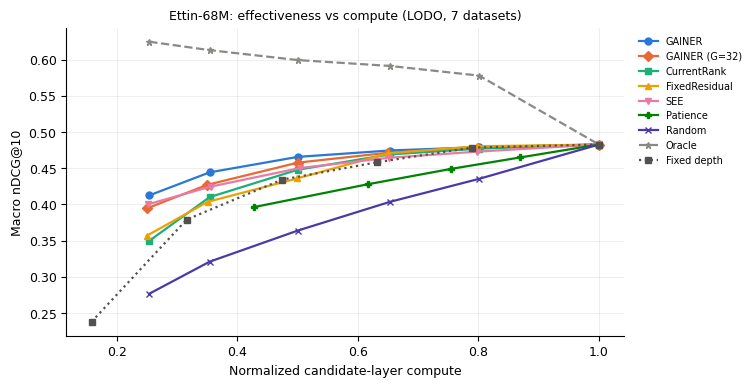

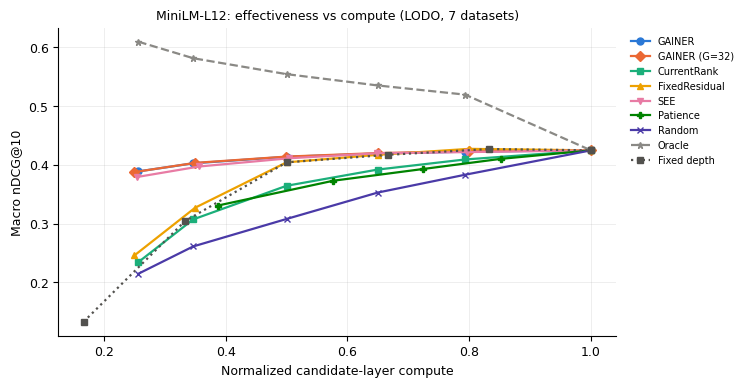

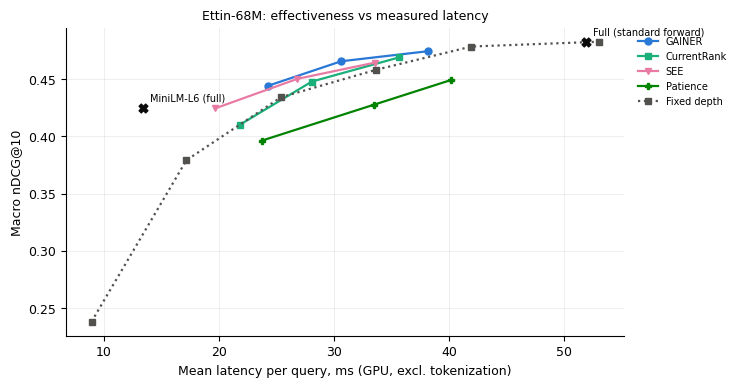

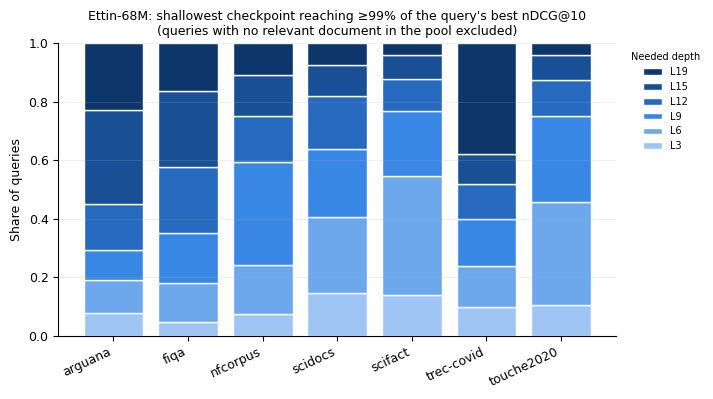

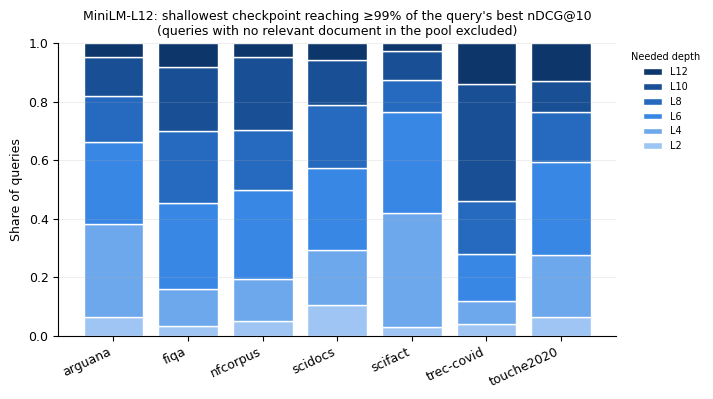

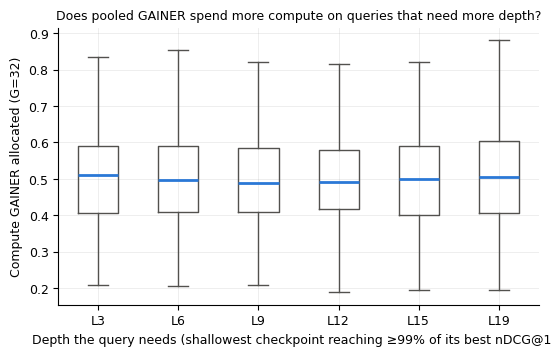

In [ ]:
SERIES_COLORS = {"GAINER": "#2a78d6", f"GAINER (G={G_MAX})": "#eb6834", "CurrentRank": "#1baf7a",
                 "FixedResidual": "#eda100", "SEE": "#e87ba4", "Patience": "#008300", "Random": "#4a3aa7",
                 "Oracle": "#8a8985", "Fixed depth": "#52514e"}
MARKERS = {"GAINER": "o", f"GAINER (G={G_MAX})": "D", "CurrentRank": "s", "FixedResidual": "^", "SEE": "v",
           "Patience": "P", "Random": "x", "Oracle": "*", "Fixed depth": "s"}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "lines.linewidth": 1.6,
                     "savefig.dpi": 300, "savefig.bbox": "tight"})

def pareto_compute(bb):
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    for method, variant, pool in CURVE_METHODS:
        lab = method if pool == 1 else f"{method} (G={pool})"
        c = curve(bb, method, variant, pool)
        c = c[c.n_ds == len(DATASETS)]
        if c.empty:
            continue
        ax.plot(c.cost, c.ndcg, marker=MARKERS[lab], markersize=5, color=SERIES_COLORS[lab], label=lab,
                linestyle="--" if method == "Oracle" else "-")
    layers = BACKBONES[bb]["checkpoints"]
    fx = [(l / layers[-1], macro(per_query(bb, f"Fixed_L{l}"))) for l in layers]
    ax.plot(*zip(*fx), marker="s", markersize=4, linestyle=":", color=SERIES_COLORS["Fixed depth"], label="Fixed depth")
    ax.set_xlabel("Normalized candidate-layer compute")
    ax.set_ylabel("Macro nDCG@10")
    ax.set_title(f"{BACKBONES[bb]['label']}: effectiveness vs compute (LODO, {len(DATASETS)} datasets)", fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.savefig(FIGS / f"fig_pareto_compute_{bb}.png"); fig.savefig(FIGS / f"fig_pareto_compute_{bb}.pdf")
    plt.show()

for bb in RUN_BACKBONES:
    pareto_compute(bb)

if not latency.empty:
    dev = "cuda" if (latency.device == "cuda").any() else "cpu"
    lt = lat_t[lat_t.device == dev]
    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    for fam in ["GAINER", "CurrentRank", "SEE", "Patience"]:
        sub = lt[lt.method.str.startswith(fam + "@")].sort_values("mean_ms")
        if len(sub):
            ax.plot(sub.mean_ms, sub.macro_ndcg_full_test, marker=MARKERS[fam], markersize=5, color=SERIES_COLORS[fam], label=fam)
    fx = lt[lt.method.str.startswith("Fixed_L")].sort_values("mean_ms")
    ax.plot(fx.mean_ms, fx.macro_ndcg_full_test, marker="s", markersize=4, linestyle=":", color=SERIES_COLORS["Fixed depth"], label="Fixed depth")
    for lab in list(SMALL_FULL_MODELS) + ["Full (standard forward)"]:
        r = lt[lt.method == lab]
        if len(r):
            ax.scatter(r.mean_ms, r.macro_ndcg_full_test, marker="X", s=40, color="#0b0b0b", zorder=3)
            ax.annotate(lab, (float(r.mean_ms.iloc[0]), float(r.macro_ndcg_full_test.iloc[0])), fontsize=7,
                        xytext=(5, 5), textcoords="offset points")
    ax.set_xlabel(f"Mean latency per query, ms ({'GPU' if dev == 'cuda' else 'CPU'}, excl. tokenization)")
    ax.set_ylabel("Macro nDCG@10")
    ax.set_title(f"{BACKBONES[MAIN_BACKBONE]['label']}: effectiveness vs measured latency", fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.savefig(FIGS / f"fig_pareto_latency_{MAIN_BACKBONE}.png"); fig.savefig(FIGS / f"fig_pareto_latency_{MAIN_BACKBONE}.pdf")
    plt.show()

# depth heterogeneity (ordinal blue ramp, 2px surface gap between stacked segments)
RAMP = ["#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]   # ordinal: shallow (light) -> deep (dark)
for bb in RUN_BACKBONES:
    layers = BACKBONES[bb]["checkpoints"]
    dd = depth_dist[depth_dist.backbone == bb].pivot(index="dataset", columns="needed_layer", values="share").reindex(columns=layers).fillna(0)
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    bottom = np.zeros(len(dd))
    for i, l in enumerate(layers):
        ax.bar(dd.index, dd[l], bottom=bottom, color=RAMP[i % len(RAMP)], edgecolor="white", linewidth=1.0, label=f"L{l}")
        bottom += dd[l].to_numpy()
    ax.set_ylim(0, 1); ax.set_ylabel("Share of queries")
    ax.set_title(f"{BACKBONES[bb]['label']}: shallowest checkpoint reaching ≥99% of the query's best nDCG@10\n"
                 "(queries with no relevant document in the pool excluded)", fontsize=9)
    handles, labels_ = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels_[::-1], fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              title="Needed depth", title_fontsize=7)
    ax.set_xticks(range(len(dd.index)))
    ax.set_xticklabels([n.replace("webis-touche2020", "touche2020") for n in dd.index], rotation=25, ha="right")
    ax.grid(axis="x", visible=False)
    fig.savefig(FIGS / f"fig_depth_heterogeneity_{bb}.png"); fig.savefig(FIGS / f"fig_depth_heterogeneity_{bb}.pdf")
    plt.show()

# allocated compute vs needed depth under pooling
if len(alloc):
    layers = BACKBONES[MAIN_BACKBONE]["checkpoints"]
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    data = [alloc.loc[alloc.needed_layer == l, "cost"].to_numpy() for l in layers]
    ax.boxplot(data, tick_labels=[f"L{l}" for l in layers], showfliers=False,
               medianprops=dict(color="#2a78d6", linewidth=2), boxprops=dict(color="#52514e"),
               whiskerprops=dict(color="#52514e"), capprops=dict(color="#52514e"))
    ax.set_xlabel("Depth the query needs (shallowest checkpoint reaching ≥99% of its best nDCG@10)")
    ax.set_ylabel(f"Compute GAINER allocated (G={G_MAX})")
    ax.set_title("Does pooled GAINER spend more compute on queries that need more depth?", fontsize=9)
    fig.savefig(FIGS / f"fig_allocated_vs_needed_{MAIN_BACKBONE}.png"); fig.savefig(FIGS / f"fig_allocated_vs_needed_{MAIN_BACKBONE}.pdf")
    plt.show()

## 14. Decision gates and run manifest
The decision gates were fixed before the run and are computed from the results.

In [ ]:
h1, h2, h3 = (primary.set_index("hypothesis").loc[h] for h in ["H1", "H2", "H3"])
pool_gain = h3["delta"]
second = [bb for bb in RUN_BACKBONES if bb != MAIN_BACKBONE]
g4 = secondary[(secondary.dataset == "MACRO") & (secondary.backbone.isin(second))]
lines = [
    f"G1  Learned allocation beats the score cascade (H1): delta = {h1['delta']:+.4f} "
    f"[{h1['ci_low']:+.4f}, {h1['ci_high']:+.4f}], Holm p = {h1['p_holm']:.4f} -> {'PASS' if h1['supported'] else 'FAIL'}",
    f"G2  Cross-query pooling adds >= +0.005 (H3): delta = {pool_gain:+.4f}, Holm p = {h3['p_holm']:.4f} -> "
    f"{'PASS: make pooling a headline contribution' if (pool_gain >= 0.005 and h3['supported']) else 'report pooling as an extension'}",
    f"G3  GAINER vs SEE at matched compute (H2): delta = {h2['delta']:+.4f}, Holm p = {h2['p_holm']:.4f} -> "
    f"{'PASS' if h2['supported'] else 'position on the exact-budget guarantee; check the latency table'}",
]
if g4.empty:
    lines.append("G4  Replication on a second backbone: not run (only one backbone in RUN_BACKBONES)")
for _, r in g4.iterrows():
    lines.append(f"G4  Replication on {BACKBONES[r.backbone]['label']}: delta = {r.delta:+.4f}, p = {r.p:.4f} -> "
                 f"{'PASS' if (r.delta > 0 and r.p < ALPHA) else 'direction only' if r.delta > 0 else 'FAIL: keep claims backbone-specific'}")
print("\n".join(lines))
if not h1["supported"]:
    print("\nPlan B applies: present the budgeted cascade + exit heads (+ pooling if G2 passes) as the contribution, "
          "and report the learned controller as a negative ablation.")

manifest = {
    "finished_utc": datetime.now(timezone.utc).isoformat(),
    "prereg_sha256": json.loads(PREREG_PATH.read_text())["sha256"],
    "versions": {"python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__,
                 "sentence_transformers": sentence_transformers.__version__, "numpy": np.__version__, "pandas": pd.__version__,
                 "bm25s": getattr(bm25s, "__version__", "?")},
    "device": torch.cuda.get_device_name(0) if DEVICE == "cuda" else platform.processor(),
    "config": {k: globals()[k] for k in ["DATASETS", "TOP_K", "EVAL_K", "MAX_LENGTH", "GAIN", "BUDGETS", "PRIMARY_BUDGET", "SEEDS",
                                         "MAIN", "ABLATIONS", "POOL_SIZES", "POOL_SHUFFLES", "BALANCE_CAP", "SOURCE_VAL_FRACTION",
                                         "HEAD_HIDDEN", "EXIT_EPOCHS", "RANK_EPOCHS", "PAIRS_PER_GROUP", "MAX_PAIRS_PER_STAGE",
                                         "SEE_EXIT_LAYER", "SEE_K", "PATIENCE_P", "PERMUTATIONS", "BOOTSTRAP", "QUICK_TRIAL"]},
    "backbones": {k: BACKBONES[k] for k in RUN_BACKBONES},
    "raw_result_files": len(list(RAW.glob("*.parquet"))),
    "gates": lines,
}
(RESULTS / "run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("\nSaved:", RESULTS / "run_manifest.json")
print("Tables:", sorted(p.name for p in TABLES.iterdir()))
print("Figures:", sorted(p.name for p in FIGS.iterdir()))

G1  Learned allocation beats the score cascade (H1): delta = +0.0178 [+0.0125, +0.0233], Holm p = 0.0000 -> PASS
G2  Cross-query pooling adds >= +0.005 (H3): delta = -0.0080, Holm p = 0.0001 -> report pooling as an extension
G3  GAINER vs SEE at matched compute (H2): delta = +0.0154, Holm p = 0.0001 -> PASS
G4  Replication on MiniLM-L12: delta = +0.0493, p = 0.0000 -> PASS

Saved: /content/drive/MyDrive/GAINER_IJACSA_Pareto_LODO/v3/results/run_manifest.json
Tables: ['allocated_vs_needed_depth.csv', 'auec.csv', 'depth_heterogeneity.csv', 'latency_vs_simulation_integrity.csv', 'leak_test_ettin68m_k50.csv', 'leak_test_minilm12_k50.csv', 'oracle_gap_closed.csv', 'pool_diagnostics.csv', 'primary_hypotheses.csv', 'secondary_tests.csv', 'seed_variability_primary_budget.csv', 'table_ablations.csv', 'table_ablations.tex', 'table_latency.csv', 'table_latency.tex', 'table_main_ettin68m.csv', 'table_main_ettin68m.tex', 'table_main_minilm12.csv', 'table_main_minilm12.tex']
Figures: ['fig_allocated_